# Домашнее задание 2. Вариант NLP: NER - детекция в тексте

**Дедлайн:** вс 22.11.2026, 23:59

В ДЗ2 вы выбираете **один** вариант: CV (детекция объектов на YOLO) или NLP (этот ноутбук). Номера задач и баллы в вариантах совпадают. NER (named entity recognition) - это детекция в тексте: найти спаны, т.е. непрерывные куски из слов, и для каждого предсказать тип сущности. Вы берете предобученный энкодер с Hugging Face Hub, находите свой датасет, приводите разметку к формату модели, дообучаете, считаете метрики и разбираете ошибки.

- Заполняйте места с `# ваш код` и ячейки «**Ответ:**». Сигнатуры функций и открытые тесты не меняйте, свои ячейки добавлять можно. Открытые тесты проверяют часть контракта, при проверке будут и другие входы
- В ответах опирайтесь на свои числа: наблюдение, объяснение, ограничение вывода. Обычно хватает 2-4 предложений. Отсутствие ожидаемого эффекта - нормальный результат, если эксперимент корректный и вы это обсудили
- Свой код обязателен в 1.2 (параметры по блокам), 2.2 (конвертация разметки + тесты), 3.1 (словарный бейзлайн), 5.1 (категоризация ошибок). Для обучения и стандартных метрик можно `transformers` (`Trainer` или свой цикл) и `seqeval`
- `FAST_MODE = True` - отладка на маленьком подмножестве, весь ноутбук не дольше 5 минут на T4. Финальный прогон - с `FAST_MODE = False`, ориентир до ~1 часа на T4. Бонусы включаются через `BONUS_TASKS`, выключенные бонусы пропускаются, даже если их ячейки пустые
- Запуск: Colab (T4) или Kaggle (GPU T4, ноутбук сам берет одну карту). Зависимости ставит первая ячейка, пины те же, что в `requirements_nlp.txt`. Укажите устройство в ячейке ниже, время обучения возвращает ваш `train_ner` (4.1)
- Только открытые модели и данные. Лицензию модели и датасета укажите в 1.1 и 2.1
- Можно документацию, материалы курса и код семинаров - укажите источник
- Сдача как в ДЗ1: PR в свой публичный GitHub-репозиторий, ссылка на него - в Google-форму (ссылку на форму дадим отдельно). В PR - ноутбук с outputs и `artifacts/metrics.json` (пишется в 5.3, перед бонусами). Датасет (`data/`), `runs/` и веса моделей не кладите, достаточно кода скачивания; файл доразметки из 6.1 - кладите
- Для полной сдачи: Restart & Run All с `FAST_MODE = False`, сохранить outputs. Если сдаете частичное решение, перечислите нерешенные задачи в ячейке ниже и приложите то, что получилось. Ошибки не скрывайте: баллы ставятся по задачам, одна ошибка не обнуляет остальные
- ДЗ индивидуальное

| раздел | задачи | баллы |
|---|---|---|
| 1. Модель | 1.1 модель и ревизия · 1.2 архитектура | 4 |
| 2. Данные | 2.1 датасет · 2.2 формат разметки | 4 |
| 3. Бейзлайн | 3.1 бейзлайн до дообучения | 2 |
| 4. Дообучение | 4.1 обучение · 4.2 метрики | 6 |
| 5. Анализ | 5.1 разбор ошибок · 5.2 абляция · 5.3 выводы | 4 |
| 6*. Бонусы | 6.1 доразметка · 6.2 другая модель · 6.3 сдвиг · 6.4 экспорт и скорость · 6.5 пороги | до +4 из 5.5 |
| итого | | 20 + 4 |

Соответствие с CV-вариантом - задачи те же, меняется «геометрия»: вместо прямоугольника на картинке - отрезок из слов в предложении.

| CV (детекция на картинке) | NLP (NER в тексте) |
|---|---|
| бокс | спан: (начало, конец, тип) в индексах слов |
| класс объекта | тип сущности (PER, ORG, LOC, ...) |
| фон | тег `O` |
| VOC / COCO -> YOLO-формат | слова и спаны -> BIO-теги под сабворды токенизатора |
| backbone -> neck -> head | эмбеддинги -> слои энкодера -> голова token classification |
| mAP по IoU | F1 по сущностям (`seqeval`, спан засчитывается при точном совпадении границ и типа) |
| ошибка локализации (IoU 0.1-0.5) | ошибка границы спана (тип верный, спаны пересекаются) |
| ошибка класса | ошибка типа |
| пропуск / лишний бокс | пропуск / лишний спан |
| порог conf | порог уверенности спана |

Внутренности трансформера (attention, устройство слоя энкодера) - тема ДЗ3. Здесь энкодер рассматривается на уровне блоков.

Примерный план: первая неделя - разделы 1-3 (модель, датасет, разметка, бейзлайн), вторая - обучение, метрики, разбор ошибок, абляция и финальный прогон.

**Сведения о сдаче.** Укажите устройство (Colab T4 / Kaggle / свое), выбранные модель и датасет (ссылка и лицензия), бонусы, внешние источники и нерешенные задачи (если есть).

**Сведения о сдаче**

- Google Colab, GPU T4. Фактическое устройство печатается при запуске и сохраняется в `artifacts/metrics.json`.
- Модель — [cointegrated/rubert-tiny2](https://huggingface.co/cointegrated/rubert-tiny2/tree/e8ed3b0c8bbf4fb6984c3de043bf7d2f4e5969ae), лицензия MIT. Это компактный предобученный русскоязычный BERT-энкодер. Для NER добавляется новая голова token classification.
- Данные — [RCC-MSU/collection3](https://huggingface.co/datasets/RCC-MSU/collection3). Карточка указывает лицензию `other` без уточнения условий. Новостной корпус основан на Persons-1000. Разметку расширили до PER, ORG и LOC с помощью Brat по правилам, близким к MUC-7. Используются готовые сплиты.
- Для обучения используется [Transformers Trainer](https://huggingface.co/docs/transformers/main_classes/trainer), для метрик по сущностям — [seqeval](https://github.com/chakki-works/seqeval).
- Абляция — заморозка энкодера. Включены бонусы 6.1–6.5. Для 6.1 используем 50 предложений из русскоязычного Викигида ([Казань](https://ru.wikivoyage.org/w/index.php?oldid=763556), [Великий Новгород](https://ru.wikivoyage.org/w/index.php?oldid=712875) и [Санкт-Петербург](https://ru.wikivoyage.org/w/index.php?oldid=785775), [CC BY-SA 4.0](https://creativecommons.org/licenses/by-sa/4.0/)). Спаны PER, ORG и LOC размечаются вручную в JSON. Для 6.2 берём [cointegrated/rubert-tiny](https://huggingface.co/cointegrated/rubert-tiny/tree/5441c5ea8026d4f6d7505ec004845409f1259fb1), лицензия MIT. В 6.4 используем [динамическую INT8-квантизацию линейных слоёв PyTorch](https://docs.pytorch.org/docs/stable/generated/torch.ao.quantization.quantize_dynamic.html).

In [1]:
# Зависимости (пины те же, что в requirements_nlp.txt). Запускайте эту ячейку первой, тогда перезапуск сессии не нужен
# Безвредный шум: строки ERROR от pip про bigframes / cudf / pyarrow на Kaggle и предупреждение про HF_TOKEN ниже (токен не нужен)
# Локально: сначала torch под свою платформу (https://pytorch.org/get-started/locally/)
%pip install -q "torch>=2.4" "transformers==5.22.1" "datasets==5.1.0" "accelerate==1.15.0" "seqeval==1.2.2" numpy matplotlib

  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Installing backend dependencies ... done
  Preparing metadata (pyproject.toml) ... done
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
cudf-cu13 26.6.0 requires pyarrow<24,>=19.0.0, but you have pyarrow 26.0.1 which is incompatible.


In [2]:
import os
os.environ.setdefault('CUDA_VISIBLE_DEVICES', '0')   # одна GPU: на Kaggle T4 x2 иначе Trainer включит DataParallel (медленнее и хуже)
import collections
import copy
import json
import math
import random
import re
import time
from html import unescape
from itertools import groupby
from pathlib import Path
from urllib.parse import urlencode
from urllib.request import Request, urlopen

import numpy as np
import matplotlib.pyplot as plt
import torch

import datasets
import transformers
from datasets import DatasetDict, load_dataset
from huggingface_hub import HfApi
from seqeval.metrics import classification_report, f1_score, precision_score, recall_score
from seqeval.metrics.sequence_labeling import get_entities
from torch.ao.quantization import quantize_dynamic
from transformers import (AutoModelForTokenClassification, AutoTokenizer, DataCollatorForTokenClassification,
                          Trainer, TrainingArguments)

In [3]:
transformers.logging.set_verbosity_error()
plt.rcParams['figure.dpi'] = 100
plt.rcParams['font.size'] = 11

print(f'torch {torch.__version__}, transformers {transformers.__version__}, datasets {datasets.__version__}')
print(f'CUDA available: {torch.cuda.is_available()}')


def get_device():
    if torch.cuda.is_available():
        return torch.device('cuda')
    if torch.backends.mps.is_available():
        return torch.device('mps')
    return torch.device('cpu')


def set_seed(seed=0):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    transformers.set_seed(seed)


device = get_device()
DEVICE_NAME = torch.cuda.get_device_name(0) if device.type == 'cuda' else device.type
set_seed(0)
print(device, DEVICE_NAME)

torch 2.14.1+cu130, transformers 5.22.1, datasets 5.1.0
CUDA available: True
cuda Tesla T4


In [4]:
FAST_MODE = False   # True - отладка, False - финальный прогон
BONUS_TASKS = {'6.1', '6.2', '6.3', '6.4', '6.5'}   # например {'6.3', '6.5'}; пустое множество отключает все бонусы
assert BONUS_TASKS <= {'6.1', '6.2', '6.3', '6.4', '6.5'}

SEED = 0
N_TRAIN = 2000 if FAST_MODE else None   # None - весь train
N_EVAL = 500 if FAST_MODE else None     # подмножество validation и test в FAST_MODE
EPOCHS = 1 if FAST_MODE else 3
MAX_LENGTH = 128                        # длина в сабвордах, длиннее - обрезается
ARTIFACTS = Path('artifacts')
ARTIFACTS.mkdir(exist_ok=True)
RUN_TIMES = {}

---
# 1. Модель

## 1.1 Модель и ревизия (1.5 балла)

Выберите предобученный энкодер на Hugging Face Hub, подходящий под язык и домен вашего датасета. Модель на Hub - это git-репозиторий: владелец может перезалить веса, токенизатор или конфиг, и `main` начнет указывать на другую версию. Поэтому зафиксируйте `revision` - полный commit hash (40 символов). Его видно во вкладке «Files and versions» -> «History» или через `HfApi().model_info(MODEL_ID).sha`.

Ориентиры для выбора (не исчерпывающий список):
- русский: `cointegrated/rubert-tiny2` (29M параметров, быстрый), `DeepPavlov/rubert-base-cased` (~180M)
- многоязычные: `FacebookAI/xlm-roberta-base` (~280M), `google-bert/bert-base-multilingual-cased` (~180M), `distilbert/distilbert-base-multilingual-cased`
- английский: `google-bert/bert-base-cased`, `FacebookAI/roberta-base` (в 1.1 задайте `TOKENIZER_KWARGS = {'add_prefix_space': True}`), `microsoft/deberta-v3-small`
- биомедицина: `dmis-lab/biobert-base-cased-v1.2`

Нужен fast-токенизатор: `word_ids()`, без которого не выровнять метки по сабвордам, есть только у него. На T4 модель до ~300M параметров дообучается на датасете в десятки тысяч предложений за минуты - десятки минут.

Нужен базовый энкодер, а не модель, уже дообученная на NER: с ней 3.1 и 4.1 теряют смысл.

In [5]:
MODEL_ID = 'cointegrated/rubert-tiny2'
REVISION = 'e8ed3b0c8bbf4fb6984c3de043bf7d2f4e5969ae'
TOKENIZER_KWARGS = {}   # для roberta-base: {'add_prefix_space': True}

In [6]:
assert MODEL_ID, 'укажите MODEL_ID'
assert re.fullmatch(r'[0-9a-f]{40}', REVISION or ''), 'REVISION - полный commit hash из 40 символов, а не main и не тег'
info = HfApi().model_info(MODEL_ID, revision=REVISION, files_metadata=True)
card = info.card_data.to_dict() if info.card_data else {}
weights = {s.rfilename: f'{s.size / 2**20:.0f} MB' for s in info.siblings if s.rfilename.endswith(('.safetensors', '.bin'))}
print(f'model:    {MODEL_ID}\nrevision: {info.sha}\nlicense:  {card.get("license")}\nlanguage: {card.get("language")}')
print(f'updated:  {info.last_modified}\nweights:  {weights}')

tokenizer = AutoTokenizer.from_pretrained(MODEL_ID, revision=REVISION, **TOKENIZER_KWARGS)
assert tokenizer.is_fast, 'нужен fast-токенизатор: word_ids() есть только у него'
print(type(tokenizer).__name__, 'vocab size', tokenizer.vocab_size)
print(tokenizer.tokenize('Петр Ильич Чайковский родился в Воткинске'))

model:    cointegrated/rubert-tiny2
revision: e8ed3b0c8bbf4fb6984c3de043bf7d2f4e5969ae
license:  mit
language: ['ru']
updated:  2025-12-30 08:33:24+00:00
weights:  {'model.safetensors': '112 MB', 'pytorch_model.bin': '112 MB'}


config.json:   0%|          | 0.00/693 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/401 [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/1.08M [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/1.74M [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/112 [00:00<?, ?B/s]

BertTokenizer vocab size 83828
['Петр', 'Ильич', 'Чайк', '##овский', 'родился', 'в', 'Вот', '##кинс', '##ке']


**Вопрос.** Почему вы выбрали эту модель: язык и данные предобучения, размер и скорость, ожидаемое качество на NER, лицензия? Сравните с 1-2 альтернативами из списка выше: размер, язык, скорость, качество по карточке. Что может сломаться в вашем ноутбуке через полгода, если не фиксировать `revision`?

**Ответ:**

Для русскоязычных новостей я выбрала rubert-tiny2 (MIT): у него русский словарь на 83 828 сабвордов и всего три слоя энкодера. При предобучении модель училась приближать представления предложений LaBSE и использовала задачу вывода по парам предложений (NLI). Для NER эти представления требуют адаптации к границам и типам сущностей. Альтернатива rubert-base-cased обучалась на русской Википедии и новостях, но у неё 12 слоёв и около 180 млн параметров против 29,1 млн у нашей модели с головой. Поэтому от tiny2 я ожидала более быстрого обучения. в моём прогоне три эпохи заняли 53,2 с. Карточки не дают сопоставимого F1 на Collection3. Полный хеш ревизии фиксирует веса, словарь и конфигурацию: обновление любого из них в ветке main может изменить токенизацию и результат повторного прогона. [rubert-tiny2](https://huggingface.co/cointegrated/rubert-tiny2) · [rubert-base-cased](https://huggingface.co/DeepPavlov/rubert-base-cased)

## 1.2 Архитектура (2.5 балла)

Энкодер для token classification на уровне блоков:

1. **эмбеддинги** - сабворд -> вектор размера hidden (таблица `vocab_size x hidden`) + позиционные эмбеддинги (у DeBERTa их нет, позиции учитываются в attention) и type-эмбеддинги (у BERT-подобных), LayerNorm, dropout. Выход `(B, T, H)`
2. **N слоев энкодера** - одинаковые по форме блоки `(B, T, H) -> (B, T, H)`, в которых токены обмениваются информацией друг с другом. Устройство слоя (attention, FFN) - ДЗ3
3. **голова token classification** - dropout + `Linear(H, K)` к каждому токену независимо, K - число BIO-тегов. Выход - logits `(B, T, K)`
4. **сборка спанов** - argmax по тегам на первом сабворде каждого слова, затем BIO -> спаны (это уже не нейросеть, а ваш код из 2.2)

Ниже модель создается с головой на `N_DEMO_LABELS = 7` тегов (O + B/I для трех типов), под ваш датасет голову пересоздает `make_model` (3.1, 4.1).

1. Реализуйте `params_by_block(model)` - число параметров по блокам: `embeddings`, `encoder` (все слои), `head` (классификатор), `other` (все остальное: у BERT и RoBERTa для token classification здесь 0, у DeBERTa - `encoder.rel_embeddings` и общий `encoder.LayerNorm`) и `layers` - список по слоям энкодера. Сумма блоков должна совпасть с общим числом параметров
2. Прогоните dummy-вход `demo_texts` (батч из двух предложений, уже разбитых на слова) через токенизатор и модель с `output_hidden_states=True`, сохраните результат токенизатора в `enc`, выход модели в `out` и выведите формы: `input_ids`, `attention_mask`, все `hidden_states`, `logits`

In [7]:
N_DEMO_LABELS = 7
demo_model = AutoModelForTokenClassification.from_pretrained(MODEL_ID, revision=REVISION, num_labels=N_DEMO_LABELS)
cfg = demo_model.config
print({k: getattr(cfg, k, None) for k in ['model_type', 'vocab_size', 'hidden_size', 'num_hidden_layers',
                                          'num_attention_heads', 'intermediate_size', 'max_position_embeddings']})
for name, module in demo_model.named_children():
    print(f'{name:<12} {type(module).__name__}')

model.safetensors: reconstructing file:   0%|          |  0.00B /  118MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/53 [00:00<?, ?it/s]

{'model_type': 'bert', 'vocab_size': 83828, 'hidden_size': 312, 'num_hidden_layers': 3, 'num_attention_heads': 12, 'intermediate_size': 600, 'max_position_embeddings': 2048}
bert         BertModel
dropout      Dropout
classifier   Linear


In [8]:
def params_by_block(model):
    # -> {'embeddings': int, 'encoder': int, 'head': int, 'other': int, 'layers': [int, ...]}
    backbone = model.base_model
    embeddings = sum(p.numel() for p in backbone.embeddings.parameters())
    layers = [sum(p.numel() for p in layer.parameters()) for layer in backbone.encoder.layer]
    encoder = sum(layers)
    head = sum(p.numel() for p in model.classifier.parameters())
    total = sum(p.numel() for p in model.parameters())
    return dict(embeddings=embeddings, encoder=encoder, head=head,
                other=total - embeddings - encoder - head, layers=layers)

In [9]:
blocks = params_by_block(demo_model)
total = sum(p.numel() for p in demo_model.parameters())
assert sum(blocks[k] for k in ['embeddings', 'encoder', 'head', 'other']) == total
assert blocks['head'] == cfg.hidden_size * N_DEMO_LABELS + N_DEMO_LABELS
assert len(blocks['layers']) == cfg.num_hidden_layers and sum(blocks['layers']) == blocks['encoder'], \
    'encoder - сумма слоев, все вне слоев (например, rel_embeddings у DeBERTa) - в other'
assert blocks['embeddings'] >= cfg.vocab_size * cfg.hidden_size
for k in ['embeddings', 'encoder', 'head', 'other']:
    print(f'{k:<11}{blocks[k]:>13,}  {blocks[k] / total:6.1%}')
print(f'{"total":<11}{total:>13,}\nper layer: {blocks["layers"]}')

embeddings    26,794,560   92.1%
encoder        2,301,552    7.9%
head               2,191    0.0%
other                  0    0.0%
total         29,098,303
per layer: [767184, 767184, 767184]


In [10]:
demo_texts = [['Петр', 'Чайковский', 'родился', 'в', 'Воткинске', '.'],
              ['ITMO', 'University', 'is', 'in', 'Saint', 'Petersburg']]
enc = tokenizer(demo_texts, is_split_into_words=True, padding=True, return_tensors='pt')
demo_model.eval()
with torch.inference_mode():
    out = demo_model(**enc, output_hidden_states=True)

for name in ('input_ids', 'attention_mask'):
    print(name, tuple(enc[name].shape))
for i, hidden_state in enumerate(out.hidden_states):
    print(f'hidden_states[{i}]', tuple(hidden_state.shape))
print('logits', tuple(out.logits.shape))

input_ids (2, 11)
attention_mask (2, 11)
hidden_states[0] (2, 11, 312)
hidden_states[1] (2, 11, 312)
hidden_states[2] (2, 11, 312)
hidden_states[3] (2, 11, 312)
logits (2, 11, 7)


In [11]:
B, T = enc['input_ids'].shape
assert B == 2 and out.logits.shape == (B, T, N_DEMO_LABELS)
assert len(out.hidden_states) == cfg.num_hidden_layers + 1
assert all(h.shape == (B, T, cfg.hidden_size) for h in out.hidden_states)

# скорость прямого прохода: батч 32 предложения x 62 слова (сколько это сабвордов - см. вывод)
x = {k: v.to(device) for k, v in tokenizer([['слово'] * 62] * 32, is_split_into_words=True, return_tensors='pt').items()}
demo_model.to(device).eval()
with torch.inference_mode():
    demo_model(**x)
    if device.type == 'cuda':
        torch.cuda.synchronize()
    start = time.perf_counter()
    for _ in range(5):
        demo_model(**x)
    if device.type == 'cuda':
        torch.cuda.synchronize()
print(f'forward 32 x {x["input_ids"].shape[1]}: {(time.perf_counter() - start) / 5 * 1000:.1f} ms на {DEVICE_NAME}')
demo_model = demo_model.cpu()

forward 32 x 64: 6.7 ms на Tesla T4


**Вопрос.** Опишите путь входа по блокам с формами тензоров из вашего вывода. Какой блок содержит больше всего параметров и почему? В каком блоке токены обмениваются информацией, а где каждый токен обрабатывается независимо? Почему `T` в logits больше числа слов?

**Ответ:**

В примере input_ids и маска имеют форму (2, 11). Эмбеддинги превращают каждую позицию в вектор из 312 чисел, три слоя энкодера сохраняют форму (2, 11, 312), а линейная голова выдаёт (2, 11, 7) — по одной оценке для каждого BIO-тега. Обмен информацией между позициями происходит в self-attention. Поиск эмбеддинга, полносвязная часть слоя и голова обрабатывают каждую позицию отдельно. На эмбеддинги приходится 26 794 560 параметров (92,1%): только таблица сабвордов содержит 83 828 строк по 312 чисел. Длина T учитывает части слов и служебные токены, в том числе [CLS] и [SEP].

---
# 2. Данные

## 2.1 Датасет (1.5 балла)

Найдите датасет для NER на Hugging Face Hub или в другом открытом источнике, подходящий под вашу модель по языку. Опишите источник, лицензию, как размечали, типы сущностей, размер и сплиты; посчитайте статистику: число сущностей каждого типа по сплитам, распределение длин спанов (в словах), длины предложений.

**Нельзя брать WikiANN ru** (`unimelb-nlp/wikiann`, конфиг `ru`) - на нем ниже показан пример формата. Другие языки WikiANN брать можно.

Подсказки - датасеты, которые на момент выдачи загружаются текущей библиотекой `datasets` (проверено 31.10.2026, `datasets` 5.1). Библиотека больше не исполняет loading-скрипты, поэтому часть датасетов грузится из служебной ветки с parquet-версией - так, как написано в списке:

Русский:
- `Babelscape/wikineural` - WikiNEuRal, PER / ORG / LOC / MISC, 9 языков; для русского сплиты `train_ru`, `val_ru`, `test_ru`; CC BY-NC-SA 4.0
- `Babelscape/multinerd` - MultiNERD, 15 типов, 10 языков, колонка `lang` - отфильтруйте `ru`; CC BY-NC-SA 4.0
- `load_dataset('RCC-MSU/collection3', revision='refs/convert/parquet')` - Collection3, новости, PER / ORG / LOC, уже `tokens` + `ner_tags`
- `undefinedhorizons/nerus_lenta` - Nerus: новости Lenta.ru с автоматической разметкой PER / LOC / ORG, только `train` и очень большой - возьмите подмножество и сами отделите validation и test
- `gusevski/factrueval2016` - FactRuEval-2016, новости; вся разметка в одной вложенной колонке `data` - разобрать в предложения, слова и BIO
- `load_dataset('iluvvatar/RuNNE', revision='refs/convert/parquet')` и то же для `iluvvatar/NEREL` - новости, 29 типов, вложенные сущности, спаны по символам в тексте. Нужны разбиение на предложения и слова (целый текст длиннее `MAX_LENGTH = 128` сабвордов, хвост обрежется), BIO и правило для вложенных (например, оставить только внешние) - самая содержательная конвертация из списка

Другие языки:
- `unimelb-nlp/wikiann` - WikiANN, 176 языков (любой, кроме `ru`), PER / ORG / LOC
- `lhoestq/conll2003`, `tomaarsen/conll2003` или `load_dataset('eriktks/conll2003', revision='refs/convert/parquet')` - CoNLL-2003, английский, PER / ORG / LOC / MISC
- `DFKI-SLT/few-nerd`, конфиг `supervised` - Few-NERD, английский, 8 крупных и 66 мелких типов; теги в IO-схеме (без `B-` и `I-`) - переведите в BIO; CC BY-SA 4.0
- `load_dataset('tner/wnut2017', revision='refs/convert/parquet')` - WNUT-17, соцсети, редкие и новые сущности; имена тегов - в файле `dataset/label.json` репозитория

Биомедицина (английский):
- `load_dataset('ncbi/ncbi_disease', revision='refs/convert/parquet')` - NCBI-disease, один тип Disease
- `load_dataset('tner/bc5cdr', revision='refs/convert/parquet')` - BC5CDR, Chemical / Disease, теги в колонке `tags`: `{"O": 0, "B-Chemical": 1, "B-Disease": 2, "I-Disease": 3, "I-Chemical": 4}`

Если `load_dataset('<id>')` падает из-за loading-скрипта, берите ветку `revision='refs/convert/parquet'` (как в списке) или сырые файлы: `load_dataset('json', data_files='hf://datasets/<id>/<путь к файлу>')`. Датасеты из списка разрешены, лицензию укажите, как в карточке.

Если сплита validation или test нет, отделите их сами (`train_test_split` с фиксированным seed). Если датасет очень большой, возьмите подмножество и укажите это.

Контракт для остального ноутбука (после 2.2): `raw` - `DatasetDict` со сплитами `train`, `validation`, `test`, у каждого примера `tokens` (список слов) и `ner_tags` (список id тегов той же длины); `LABEL_NAMES` - список BIO-тегов, `LABEL_NAMES[i]` - тег с id `i`, тег `O` обязателен.

Если у `ner_tags` нет имен тегов (в `features` список чисел, а не `ClassLabel`; так у WikiNEuRal, MultiNERD и `lhoestq/conll2003`), составьте `LABEL_NAMES` вручную по карточке датасета. Например, у WikiNEuRal: `['O', 'B-PER', 'I-PER', 'B-ORG', 'I-ORG', 'B-LOC', 'I-LOC', 'B-MISC', 'I-MISC']`.

In [12]:
# пример формата на WikiANN ru (этот датасет брать нельзя)
example = load_dataset('unimelb-nlp/wikiann', 'ru', split='validation[:3]')
print(example)
print(example.features['ner_tags'].feature.names)
for ex in example:
    print(list(zip(ex['tokens'], ex['ner_tags'])), ex['spans'])

README.md:   0%|          | 0.00/158k [00:00<?, ?B/s]

ru/validation-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B /  809kB            

ru/validation-00000-of-00001.parquet: downloading bytes:           |  0.00B            

ru/test-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B /  816kB            

ru/test-00000-of-00001.parquet: downloading bytes:           |  0.00B            

ru/train-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B / 1.63MB            

ru/train-00000-of-00001.parquet: downloading bytes:           |  0.00B            

Generating validation split:   0%|          | 0/10000 [00:00<?, ? examples/s]

Generating test split:   0%|          | 0/10000 [00:00<?, ? examples/s]

Generating train split:   0%|          | 0/20000 [00:00<?, ? examples/s]

Dataset({
    features: ['tokens', 'ner_tags', 'langs', 'spans'],
    num_rows: 3
})
['O', 'B-PER', 'I-PER', 'B-ORG', 'I-ORG', 'B-LOC', 'I-LOC']
[('Отличился', 0), ('во', 0), ('время', 0), ('боёв', 0), ('в', 0), ('Германии', 5), ('.', 0)] ['LOC: Германии']
[('1920—1922', 0), ('—', 0), ('техник', 0), ('военно-гидротехнического', 0), ('отряда', 0), ('(', 0), ('Чернигов', 5), (')', 0), (',', 0)] ['LOC: Чернигов']
[('Нагибин', 1), (',', 2), ('Владимир', 2), ('Владимирович', 2)] ['PER: Нагибин , Владимир Владимирович']


In [13]:
DATASET_ID, DATASET_CONFIG = 'RCC-MSU/collection3', None
raw = load_dataset(DATASET_ID, DATASET_CONFIG, revision='refs/convert/parquet')
LABEL_NAMES = ['O', 'B-PER', 'I-PER', 'B-ORG', 'I-ORG', 'B-LOC', 'I-LOC']

default/train/0000.parquet: reconstructing file:   0%|          |  0.00B / 1.03MB            

default/train/0000.parquet: downloading bytes:           |  0.00B            

0000.parquet:   0%|          | 0.00/245k [00:00<?, ?B/s]

0000.parquet:   0%|          | 0.00/219k [00:00<?, ?B/s]

Generating train split: 0 examples [00:00, ? examples/s]

Generating validation split: 0 examples [00:00, ? examples/s]

Generating test split: 0 examples [00:00, ? examples/s]

In [14]:
# ваша статистика: сущности по типам и сплитам, длины спанов в словах, длины предложений
entity_types = sorted({tag[2:] for tag in LABEL_NAMES if tag != 'O'})
for split, ds in raw.items():
    by_type = collections.Counter()
    span_lengths = collections.Counter()
    sentence_lengths = []

    for ex in ds:
        sentence_lengths.append(len(ex['tokens']))
        tags = [LABEL_NAMES[tag_id] for tag_id in ex['ner_tags']]
        for kind, start, last in get_entities(tags):
            by_type[kind] += 1
            span_lengths[last - start + 1] += 1

    print(f'\n{split}: {len(ds)} предложений')
    print('Сущности по типам:', {kind: by_type[kind] for kind in entity_types})
    print('Длина спана → число спанов:', dict(sorted(span_lengths.items())))
    print('Длина предложения в словах:',
          dict(zip(['min', 'p25', 'median', 'p75', 'p95', 'max'],
                   np.percentile(sentence_lengths, [0, 25, 50, 75, 95, 100]).round(1).tolist())))


train: 9301 предложений
Сущности по типам: {'LOC': 4881, 'ORG': 5960, 'PER': 7406}
Длина спана → число спанов: {1: 9025, 2: 6124, 3: 2068, 4: 373, 5: 206, 6: 238, 7: 71, 8: 68, 9: 21, 10: 24, 11: 10, 12: 4, 13: 6, 14: 2, 15: 3, 16: 3, 18: 1}
Длина предложения в словах: {'min': 1.0, 'p25': 12.0, 'median': 18.0, 'p75': 26.0, 'p95': 41.0, 'max': 256.0}

validation: 2153 предложений
Сущности по типам: {'LOC': 1168, 'ORG': 1308, 'PER': 1641}
Длина спана → число спанов: {1: 2110, 2: 1344, 3: 453, 4: 81, 5: 43, 6: 52, 7: 13, 8: 11, 9: 6, 10: 2, 12: 1, 13: 1}
Длина предложения в словах: {'min': 1.0, 'p25': 12.0, 'median': 18.0, 'p75': 26.0, 'p95': 41.0, 'max': 118.0}

test: 1922 предложений
Сущности по типам: {'LOC': 1175, 'ORG': 1256, 'PER': 1570}
Длина спана → число спанов: {1: 1951, 2: 1306, 3: 540, 4: 86, 5: 31, 6: 55, 7: 11, 8: 9, 9: 5, 10: 4, 11: 3}
Длина предложения в словах: {'min': 1.0, 'p25': 12.0, 'median': 19.0, 'p75': 27.0, 'p95': 42.0, 'max': 122.0}


**Вопрос.** Откуда датасет, под какой лицензией и как его размечали (вручную, автоматически, полуавтоматически)? Какие типы сущностей, сколько их по сплитам, какие типы редкие? Какие особенности данных (длина спанов, длина предложений, шум разметки) могут повлиять на обучение?

**Ответ:**

Collection3 основан на новостях Persons-1000. К исходным упоминаниям людей добавили ручную разметку в Brat по правилам, близким к MUC-7. Команда DeepPavlov перевела её в IOB2 и подготовила сплиты. В карточке корпуса лицензия указана как `other`. [Карточка Collection3](https://huggingface.co/datasets/RCC-MSU/collection3)

| Сплит | Предложения | PER | ORG | LOC |
|---|---:|---:|---:|---:|
| Train | 9 301 | 7 406 | 5 960 | 4 881 |
| Validation | 2 153 | 1 641 | 1 308 | 1 168 |
| Test | 1 922 | 1 570 | 1 256 | 1 175 |

Во всех сплитах чаще всего встречаются люди, реже всего — места. В train 15 149 из 18 247 спанов состоят из одного-двух слов, поэтому примеров для изучения границ длинных названий заметно меньше. Медианная длина предложения — 18 слов, максимум — 256. В длинных предложениях часть разметки может оказаться за пределом входа модели.

## 2.2 Формат разметки (2.5 балла)

Модель предсказывает тег для каждого **сабворда**, а разметка дана по **словам** (или спанами по символам). Нужны две конвертации и тесты к ним.

1. `bio_to_spans(tags)` - BIO-теги слов -> список спанов `(start, end, type)`, `end` не включается. `B-X` начинает спан, `I-X` продолжает спан того же типа, иначе начинает новый (так делает `seqeval` в режиме по умолчанию), `O` закрывает спан. Тип может содержать дефис (`B-art-film` -> `art-film`)
2. `spans_to_bio(spans, n_words)` - обратно: спаны -> BIO-теги длины `n_words`
3. `align_labels(word_labels, word_ids, b_to_i=None)` - метки слов -> метки сабвордов. `word_ids` - выход `tokenizer(...).word_ids(i)`: номер слова для каждого сабворда, `None` у спецтокенов. По умолчанию метка слова ставится на его первый сабворд, спецтокены и продолжения слова получают `-100` (cross-entropy их игнорирует). Если передан словарь `b_to_i` (id тега `B-X` -> id тега `I-X`), метку получают все сабворды слова, у продолжений `B-X` заменяется на `I-X` - это вариант для абляции 5.2

Если ваш датасет не в формате «слова + BIO» (спаны по символам, IO-теги, CoNLL-текст), сначала приведите его к контракту из 2.1 и проверьте конвертацию на примерах глазами. Если датасет уже в BIO, сделайте обратную конвертацию: BIO -> спаны в JSON (`data/<split>_spans.jsonl`), прочитайте файл обратно, сконвертируйте в BIO и проверьте, что получилось то же самое (если в исходнике есть `I-X` без `B-X`, дословно не совпадет: сравните спаны и посчитайте такие предложения).

In [15]:
def bio_to_spans(tags):
    # ['B-PER', 'I-PER', 'O', 'B-LOC'] -> [(0, 2, 'PER'), (3, 4, 'LOC')]
    spans = []
    start, active_type = None, None
    for pos, tag in enumerate([*tags, 'O']):
        prefix, _, kind = tag.partition('-')
        if prefix == 'I' and active_type == kind:
            continue
        if active_type is not None:
            spans.append((start, pos, active_type))
        start, active_type = (None, None) if prefix == 'O' else (pos, kind)
    return spans


def spans_to_bio(spans, n_words):
    # [(0, 2, 'PER')], 3 -> ['B-PER', 'I-PER', 'O']
    tags = ['O'] * n_words
    for start, end, kind in spans:
        tags[start] = f'B-{kind}'
        tags[start + 1:end] = [f'I-{kind}'] * (end - start - 1)
    return tags


def align_labels(word_labels, word_ids, b_to_i=None):
    # word_labels: id тегов слов; word_ids: номер слова для каждого сабворда (None - спецтокен) -> метки сабвордов
    labels = []
    seen = set()
    for word_id in word_ids:
        if word_id is None:
            labels.append(-100)
        elif word_id not in seen:
            labels.append(word_labels[word_id])
            seen.add(word_id)
        elif b_to_i is None:
            labels.append(-100)
        else:
            tag_id = word_labels[word_id]
            labels.append(b_to_i.get(tag_id, tag_id))
    return labels

In [16]:
tags = ['B-PER', 'I-PER', 'O', 'B-LOC', 'B-LOC', 'I-LOC', 'O', 'B-ORG']
assert bio_to_spans(tags) == [(0, 2, 'PER'), (3, 4, 'LOC'), (4, 6, 'LOC'), (7, 8, 'ORG')]
assert spans_to_bio(bio_to_spans(tags), len(tags)) == tags
assert bio_to_spans(['O', 'I-PER', 'I-PER', 'O']) == [(1, 3, 'PER')]       # I- без B- начинает спан
assert bio_to_spans(['B-PER', 'I-LOC', 'I-LOC']) == [(0, 1, 'PER'), (1, 3, 'LOC')]
assert bio_to_spans(['B-art-film', 'I-art-film', 'O']) == [(0, 2, 'art-film')]
assert bio_to_spans([]) == [] and bio_to_spans(['O'] * 3) == [] and spans_to_bio([], 2) == ['O', 'O']

rng = random.Random(0)
for _ in range(2000):   # туда-обратно на случайных спанах
    n, pos, spans = rng.randint(0, 15), 0, []
    while True:
        start = pos + rng.randint(0, 3)
        end = start + rng.randint(1, 4)
        if end > n:
            break
        spans.append((start, end, rng.choice(['PER', 'LOC', 'ORG'])))
        pos = end
    assert bio_to_spans(spans_to_bio(spans, n)) == spans, spans

word_ids = [None, 0, 0, 1, 2, 2, 2, None]
assert align_labels([1, 0, 3], word_ids) == [-100, 1, -100, 0, 3, -100, -100, -100]
assert align_labels([1, 0, 3], word_ids, b_to_i={1: 2, 3: 4}) == [-100, 1, 2, 0, 3, 4, 4, -100]
assert align_labels([2, 6], [None, 0, 0, 1, None], b_to_i={1: 2, 5: 6}) == [-100, 2, 2, 6, -100]
assert align_labels([5, 6, 0], [None, 0, None]) == [-100, 5, -100]        # обрезка по MAX_LENGTH
print('ok')

ok


In [17]:
# если датасет не в формате «слова + BIO»: конвертация в контракт из 2.1
# если уже в BIO: экспорт в спаны JSON (data/<split>_spans.jsonl), чтение обратно, BIO, сравнение с исходным
data_dir = Path('data')
data_dir.mkdir(exist_ok=True)
for split, ds in raw.items():
    path = data_dir / f'{split}_spans.jsonl'
    with path.open('w', encoding='utf-8') as stream:
        for ex in ds:
            tags = [LABEL_NAMES[tag_id] for tag_id in ex['ner_tags']]
            assert len(tags) == len(ex['tokens'])
            record = {'tokens': ex['tokens'], 'spans': bio_to_spans(tags)}
            stream.write(json.dumps(record, ensure_ascii=False) + '\n')

    changed_tags = 0
    with path.open(encoding='utf-8') as stream:
        for ex, line in zip(ds, stream, strict=True):
            record = json.loads(line)
            assert record['tokens'] == ex['tokens']
            spans = [tuple(span) for span in record['spans']]
            source = [LABEL_NAMES[tag_id] for tag_id in ex['ner_tags']]
            restored = spans_to_bio(spans, len(record['tokens']))
            assert bio_to_spans(restored) == bio_to_spans(source)
            changed_tags += restored != source
    print(f'{split}: спаны совпали для {len(ds)} предложений, в {changed_tags} случаях BIO нормализован')

train: спаны совпали для 9301 предложений, в 5 случаях BIO нормализован
validation: спаны совпали для 2153 предложений, в 0 случаях BIO нормализован
test: спаны совпали для 1922 предложений, в 1 случаях BIO нормализован


In [18]:
assert isinstance(raw, DatasetDict) and isinstance(LABEL_NAMES, list), 'raw и LABEL_NAMES - из 2.1 (после конвертации в 2.2)'
assert {'train', 'validation', 'test'} <= set(raw), 'нужны сплиты train / validation / test'
assert {'tokens', 'ner_tags'} <= set(raw['train'].column_names)
assert 'O' in LABEL_NAMES and all(re.fullmatch(r'O|[BI]-.+', t) for t in LABEL_NAMES), LABEL_NAMES
label2id = {t: i for i, t in enumerate(LABEL_NAMES)}
id2label = dict(enumerate(LABEL_NAMES))
ENTITY_TYPES = sorted({t[2:] for t in LABEL_NAMES if t != 'O'})
B_TO_I = {label2id[t]: label2id['I-' + t[2:]] for t in LABEL_NAMES if t.startswith('B-') and 'I-' + t[2:] in label2id}


def subset(ds, n):
    return ds if n is None else ds.shuffle(seed=SEED).select(range(min(n, len(ds))))


data = DatasetDict(train=subset(raw['train'], N_TRAIN), validation=subset(raw['validation'], N_EVAL),
                   test=subset(raw['test'], N_EVAL))


def tokenize_and_align(batch, tok=None, label_all_subwords=False):
    tok = tok or tokenizer
    enc = tok(batch['tokens'], is_split_into_words=True, truncation=True, max_length=MAX_LENGTH)
    enc['labels'] = [align_labels(tags, enc.word_ids(i), B_TO_I if label_all_subwords else None)
                     for i, tags in enumerate(batch['ner_tags'])]
    return enc


tokenized = data.map(tokenize_and_align, batched=True, remove_columns=data['train'].column_names)
print(data)
print('ENTITY_TYPES', ENTITY_TYPES)

# проверка на реальных данных: метки первых сабвордов восстанавливают метки слов, спаны совпадают
n_truncated = n_lost_words = n_checked = 0
for ex in data['train']:
    enc = tokenizer(ex['tokens'], is_split_into_words=True, truncation=True, max_length=MAX_LENGTH)
    ids = enc.word_ids()
    labels = align_labels(ex['ner_tags'], ids)
    got = {w: l for w, l in zip(ids, labels) if l != -100}
    assert got == {w: ex['ner_tags'][w] for w in set(ids) - {None}}
    if len(ids) == MAX_LENGTH:
        full = tokenizer(ex['tokens'], is_split_into_words=True, truncation=False)
        n_truncated += len(full['input_ids']) > MAX_LENGTH
    n_lost = len(ex['tokens']) - len(got)
    n_lost_words += n_lost
    if n_lost == 0:
        back = [LABEL_NAMES[got[w]] for w in range(len(ex['tokens']))]
        assert bio_to_spans(back) == bio_to_spans([LABEL_NAMES[i] for i in ex['ner_tags']])
        n_checked += 1
print(f'train: проверено {n_checked} предложений, обрезано по MAX_LENGTH {n_truncated}, слов без сабвордов или за обрезкой {n_lost_words}')

ex = data['train'][0]
enc = tokenizer(ex['tokens'], is_split_into_words=True, truncation=True, max_length=MAX_LENGTH)
for sub, w, l in zip(enc.tokens(), enc.word_ids(), align_labels(ex['ner_tags'], enc.word_ids())):
    print(f'{sub:<16}{str(w):>5}  {LABEL_NAMES[l] if l != -100 else -100}')

Map:   0%|          | 0/9301 [00:00<?, ? examples/s]

Map:   0%|          | 0/2153 [00:00<?, ? examples/s]

Map:   0%|          | 0/1922 [00:00<?, ? examples/s]

DatasetDict({
    train: Dataset({
        features: ['id', 'tokens', 'ner_tags'],
        num_rows: 9301
    })
    validation: Dataset({
        features: ['id', 'tokens', 'ner_tags'],
        num_rows: 2153
    })
    test: Dataset({
        features: ['id', 'tokens', 'ner_tags'],
        num_rows: 1922
    })
})
ENTITY_TYPES ['LOC', 'ORG', 'PER']
train: проверено 9288 предложений, обрезано по MAX_LENGTH 10, слов без сабвордов или за обрезкой 434
[CLS]            None  -100
До                  0  O
##полнение          0  -100
:                   1  O
Д                   2  B-PER
.                   3  I-PER
Медведев            4  I-PER
присвоил            5  O
звания              6  O
сотрудников         7  O
полиции             8  O
и                   9  O
перена             10  O
##зна              10  -100
##чил              10  -100
14                 11  O
руководителей      12  O
УВД                13  B-ORG
,                  14  O
ГУВД               15  B-ORG
и             

**Вопрос.** Почему метка ставится только на первый сабворд, а остальным -100, и что -100 делает в loss? Сколько предложений обрезано по `MAX_LENGTH` и сколько слов не получили ни одного сабворда - как это повлияет на метрику? Какие проблемы нашлись при конвертации вашего датасета (невалидный BIO, пересекающиеся или вложенные спаны, расхождение токенизации)?

**Ответ:**

Одна метка на первом сабворде даёт каждому представленному слову один вклад в loss. Cross-entropy игнорирует позиции с меткой −100, включая продолжения слов и служебные токены. В сохранённом прогоне 10 предложений train достигли лимита в 128 сабвордов. У 13 из 9 301 предложения представление оказалось неполным: после токенизации отсутствовали 434 слова. При предсказании таким словам присваивается O, поэтому сущность в пропущенном фрагменте может быть потеряна целиком. При конвертации BIO → спаны → BIO границы и типы сохранились во всех сплитах. Нормализация некорректных переходов BIO изменила запись тегов в пяти предложениях train и одном test. Исходная пословная разметка плоская.

---
# 3. Бейзлайн

## 3.1 Бейзлайн до дообучения (2 балла)

Метрики считаются по словам: тег слова - предсказание на его первом сабворде (функция `predict_word_tags` ниже). F1 по сущностям - `seqeval`: спан засчитывается, только если совпали обе границы и тип.

1. Реализуйте словарный бейзлайн: `fit_majority_tagger` запоминает для каждого слова из train самый частый его тег, `predict_majority` размечает предложение, незнакомые слова получают `O`
2. Посчитайте метрики бейзлайна и энкодера со случайно инициализированной головой (без дообучения) на validation

In [19]:
@torch.no_grad()
def predict_word_tags(model, tokens_list, tok=None, batch_size=64, return_probs=False, dev=None):
    # теги слов по первому сабворду; слова без сабвордов или за MAX_LENGTH получают 'O' (вероятность 1)
    tok, dev = tok or tokenizer, dev or device
    tokens_list = [list(ws) for ws in tokens_list]
    model.eval().to(dev)
    all_tags, all_probs = [], []
    for start in range(0, len(tokens_list), batch_size):
        batch = tokens_list[start:start + batch_size]
        enc = tok(batch, is_split_into_words=True, truncation=True, max_length=MAX_LENGTH, padding=True, return_tensors='pt')
        probs = model(**{k: v.to(dev) for k, v in enc.items()}).logits.float().softmax(-1).cpu()
        conf, best = probs.max(-1)
        for i, words in enumerate(batch):
            tags, word_conf, seen = ['O'] * len(words), [1.0] * len(words), set()
            for pos, w in enumerate(enc.word_ids(i)):
                if w is None or w in seen:
                    continue
                seen.add(w)
                tags[w], word_conf[w] = model.config.id2label[int(best[i, pos])], float(conf[i, pos])
            all_tags.append(tags)
            all_probs.append(word_conf)
    return (all_tags, all_probs) if return_probs else all_tags


def entity_scores(gold, pred):
    return dict(f1_micro=f1_score(gold, pred, average='micro', zero_division=0),
                f1_macro=f1_score(gold, pred, average='macro', zero_division=0),
                precision=precision_score(gold, pred, zero_division=0),
                recall=recall_score(gold, pred, zero_division=0))


def make_model(model_id=None, revision=None):
    return AutoModelForTokenClassification.from_pretrained(
        model_id or MODEL_ID, revision=revision or REVISION,
        num_labels=len(LABEL_NAMES), id2label=id2label, label2id=label2id)


val_tokens = [list(ws) for ws in data['validation']['tokens']]
val_gold = [[LABEL_NAMES[i] for i in tags] for tags in data['validation']['ner_tags']]

In [20]:
def fit_majority_tagger(tokens_list, tags_list):
    # -> dict: слово -> самый частый тег этого слова в train
    counts = collections.defaultdict(collections.Counter)
    for words, tags in zip(tokens_list, tags_list, strict=True):
        for word, tag in zip(words, tags, strict=True):
            counts[word][tag] += 1
    return {word: tags.most_common(1)[0][0] for word, tags in counts.items()}


def predict_majority(tagger, words):
    # -> список тегов той же длины; незнакомое слово -> 'O'
    return [tagger.get(word, 'O') for word in words]

In [21]:
toy_tokens = [['Анна', 'живет', 'в', 'Москве'], ['Москве', 'не', 'до', 'сна'], ['Анна', 'Каренина'], ['в', 'Москве']]
toy_tags = [['B-PER', 'O', 'O', 'B-LOC'], ['B-LOC', 'O', 'O', 'O'], ['B-PER', 'I-PER'], ['O', 'B-ORG']]
toy = fit_majority_tagger(toy_tokens, toy_tags)
assert toy['Москве'] == 'B-LOC' and toy['Анна'] == 'B-PER' and toy['Каренина'] == 'I-PER'
assert fit_majority_tagger([['Ленина']] * 4, [['B-LOC'], ['B-PER'], ['B-PER'], ['B-ORG']])['Ленина'] == 'B-PER'   # самый частый тег, а не первый или последний
assert predict_majority(toy, ['Анна', 'из', 'Москве']) == ['B-PER', 'O', 'B-LOC']
assert predict_majority(toy, []) == []

train_gold = [[LABEL_NAMES[i] for i in tags] for tags in data['train']['ner_tags']]
tagger = fit_majority_tagger(data['train']['tokens'], train_gold)
majority_pred = [predict_majority(tagger, words) for words in val_tokens]

set_seed(SEED)
random_head_model = make_model()
random_head_pred = predict_word_tags(random_head_model, val_tokens)
del random_head_model

baseline = {
    'majority': entity_scores(val_gold, majority_pred),
    'random_head': entity_scores(val_gold, random_head_pred),
}
print('Validation')
for name, scores in baseline.items():
    print(name, {metric: round(value, 4) for metric, value in scores.items()})
print('Теги случайной головы:', collections.Counter(tag for tags in random_head_pred for tag in tags))

Loading weights:   0%|          | 0/53 [00:00<?, ?it/s]

Validation
majority {'f1_micro': np.float64(0.5613), 'f1_macro': np.float64(0.5786), 'precision': np.float64(0.5626), 'recall': np.float64(0.5601)}
random_head {'f1_micro': np.float64(0.0381), 'f1_macro': np.float64(0.0353), 'precision': np.float64(0.0223), 'recall': np.float64(0.1304)}
Теги случайной головы: Counter({'O': 11544, 'I-PER': 11459, 'B-PER': 8688, 'I-LOC': 4833, 'B-LOC': 3053, 'I-ORG': 2511, 'B-ORG': 1768})


**Вопрос.** Какой F1 у словарного бейзлайна и почему он такой (вспомните, как размечен ваш датасет и как часто сущности повторяются)? Что предсказывает энкодер со случайной головой и почему его F1 близок к нулю, хотя энкодер предобучен?

**Ответ:**

На validation словарь дал entity micro-F1 0,5613 при близких precision и recall (0,5626 и 0,5601). Повторяющиеся в новостях имена и названия можно узнать по словоформе, но для новой формы словарь возвращает O, а у знакомой не различает значения по контексту. У случайной головы F1 составил 0,0381: она часто ставила I-PER (11 459 слов) и почти так же часто O (11 544). Предобучение дало энкодеру представления языка, но случайные веса головы ещё не связывают их с семью BIO-тегами, поэтому точные совпадения спанов редки.

---
# 4. Дообучение

## 4.1 Обучение (3 балла)

Реализуйте `train_ner`: дообучение модели на `tokenized['train']` с оценкой loss на `tokenized['validation']` по ходу обучения (не реже ~10 раз за обучение, чтобы получились кривые). Можно `Trainer` + `DataCollatorForTokenClassification` (он дополняет `labels` значением -100) или свой цикл. Параметр `freeze_encoder=True` замораживает все, кроме головы - он нужен для абляции 5.2. Функция возвращает `(history, seconds)`: `history` - список словарей с ключами `step` и `loss` (train) или `eval_loss`, как `trainer.state.log_history`.

Гиперпараметры выберите и обоснуйте: learning rate (у base-моделей обычно 2e-5 - 5e-5, маленьким моделям нужен больше), batch size, число эпох, warmup, weight decay, `fp16` на GPU.

В transformers 5 аргументы называются `eval_strategy` (не `evaluation_strategy`) и `processing_class` (не `tokenizer`), туториалы под версию 4 с ними падают. Чекпойнты не нужны: `save_strategy='no'`.

In [22]:
LR = 2e-4          # подобрано под rubert-tiny2; у base-моделей обычно 2e-5 - 5e-5, выберите под свою модель
BATCH_SIZE = 32    # уменьшите, если не влезает в память T4


def train_ner(model, train_ds, eval_ds, epochs=EPOCHS, lr=LR, batch_size=BATCH_SIZE, freeze_encoder=False,
              tok=None, out_dir='runs/main'):
    # -> (history, seconds); history - список dict со 'step' и 'loss' или 'eval_loss'
    tok = tok or tokenizer
    model.requires_grad_(not freeze_encoder)
    model.classifier.requires_grad_(True)

    total_steps = math.ceil(len(train_ds) / batch_size) * epochs
    interval = max(1, total_steps // 10)
    use_cuda = device.type == 'cuda'
    args = TrainingArguments(
        output_dir=out_dir,
        num_train_epochs=epochs,
        learning_rate=lr,
        per_device_train_batch_size=batch_size,
        per_device_eval_batch_size=batch_size,
        weight_decay=0.01,
        warmup_steps=math.ceil(0.1 * total_steps),
        lr_scheduler_type='linear',
        optim='adamw_torch',
        fp16=use_cuda,
        eval_strategy='steps',
        eval_steps=interval,
        logging_strategy='steps',
        logging_steps=interval,
        prediction_loss_only=True,
        save_strategy='no',
        report_to=[],
        seed=SEED,
        data_seed=SEED,
    )
    collator = DataCollatorForTokenClassification(tok, pad_to_multiple_of=8 if use_cuda else None)
    trainer = Trainer(model=model, args=args, train_dataset=train_ds, eval_dataset=eval_ds,
                      processing_class=tok, data_collator=collator)

    start = time.perf_counter()
    trainer.train()
    return trainer.state.log_history, time.perf_counter() - start

Loading weights:   0%|          | 0/53 [00:00<?, ?it/s]

{'loss': '0.7092', 'grad_norm': '1.707', 'learning_rate': '0.0001932', 'epoch': '0.299'}
{'eval_loss': '0.1329', 'eval_runtime': '3.096', 'eval_samples_per_second': '695.5', 'eval_steps_per_second': '21.97', 'epoch': '0.299'}
{'loss': '0.1152', 'grad_norm': '1.756', 'learning_rate': '0.0001786', 'epoch': '0.5979'}
{'eval_loss': '0.0729', 'eval_runtime': '1.211', 'eval_samples_per_second': '1778', 'eval_steps_per_second': '56.16', 'epoch': '0.5979'}
{'loss': '0.0784', 'grad_norm': '0.8545', 'learning_rate': '0.0001564', 'epoch': '0.8969'}
{'eval_loss': '0.05305', 'eval_runtime': '3.021', 'eval_samples_per_second': '712.7', 'eval_steps_per_second': '22.51', 'epoch': '0.8969'}
{'loss': '0.04839', 'grad_norm': '0.798', 'learning_rate': '0.0001343', 'epoch': '1.196'}
{'eval_loss': '0.04614', 'eval_runtime': '0.65', 'eval_samples_per_second': '3312', 'eval_steps_per_second': '104.6', 'epoch': '1.196'}
{'loss': '0.04291', 'grad_norm': '1.354', 'learning_rate': '0.0001121', 'epoch': '1.495'}
{

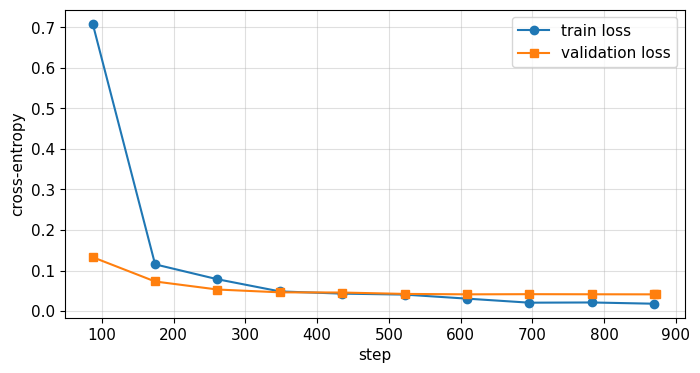

In [23]:
set_seed(SEED)
model = make_model()
history, train_seconds = train_ner(model, tokenized['train'], tokenized['validation'])
RUN_TIMES['train_main_sec'] = train_seconds
train_curve = [(h['step'], h['loss']) for h in history if 'loss' in h]
eval_curve = [(h['step'], h['eval_loss']) for h in history if 'eval_loss' in h]
assert len(train_curve) >= 2 and len(eval_curve) >= 2, 'логируйте train и eval loss по ходу обучения'
print(f'обучение: {train_seconds:.1f} c на {DEVICE_NAME}, {len(tokenized["train"])} предложений, {EPOCHS} эпох(а)')

plt.figure(figsize=(8, 4))
plt.plot(*zip(*train_curve), 'o-', label='train loss')
plt.plot(*zip(*eval_curve), 's-', label='validation loss')
plt.xlabel('step')
plt.ylabel('cross-entropy')
plt.legend()
plt.grid(True, alpha=0.4)
plt.show()

**Вопрос.** Почему выбраны такие гиперпараметры? Что видно на кривых: есть ли переобучение, нужно ли больше эпох? Сколько заняло обучение и на каком устройстве?

**Ответ:**

Для компактного энкодера выбраны learning rate 0,0002 и batch size 32, который помещается в память T4. Разогрев на первых 10% шагов смягчает начальные обновления, затем learning rate линейно уменьшается. Weight decay 0,01 ограничивает рост весов, а FP16 экономит память GPU. За три эпохи на 9 301 предложении обучение заняло 53,2 с. Между первой проверкой и концом второй эпохи validation loss снизился примерно с 0,133 до 0,041, затем колебался около 0,041, хотя train loss продолжал уменьшаться до 0,018. Устойчивого ухудшения на validation не видно, но и оснований добавлять эпохи по этой кривой мало.

## 4.2 Метрики (3 балла)

1. Посчитайте на validation и test отчет `seqeval` по типам (P/R/F1, support), micro и macro F1
2. Реализуйте `token_f1(gold, pred)` - micro-F1 по словам: верное срабатывание - слово, у которого предсказанный тег не `O` и совпадает с истинным; тег `O` в precision и recall не участвует; если не-`O` слов нет ни в gold, ни в pred, функция возвращает 0.0
3. Сравните токенный F1 и F1 по сущностям и объясните разницу

In [24]:
def token_f1(gold, pred):
    # gold, pred: списки списков BIO-тегов -> micro-F1 по словам без тега O
    true_positive = gold_positive = pred_positive = 0
    for gold_tags, pred_tags in zip(gold, pred, strict=True):
        for expected, actual in zip(gold_tags, pred_tags, strict=True):
            gold_positive += expected != 'O'
            pred_positive += actual != 'O'
            true_positive += expected != 'O' and expected == actual
    denominator = gold_positive + pred_positive
    return 2 * true_positive / denominator if denominator else 0.0

In [25]:
g, p = [['B-PER', 'I-PER', 'O', 'B-LOC']], [['B-PER', 'O', 'O', 'B-LOC']]
assert abs(token_f1(g, p) - 0.8) < 1e-9                       # 2 верных слова из 2 предсказанных и 3 истинных
assert abs(f1_score(g, p) - 0.5) < 1e-9                       # а по сущностям верна одна из двух
assert token_f1([['O', 'O']], [['O', 'O']]) == 0.0 and token_f1(g, g) == 1.0

def evaluate_ner(gold, pred, split):
    scores = entity_scores(gold, pred)
    scores['token_f1'] = token_f1(gold, pred)
    report = classification_report(gold, pred, output_dict=True, zero_division=0)
    scores['per_type'] = {
        kind: report.get(kind, {'precision': 0.0, 'recall': 0.0, 'f1-score': 0.0, 'support': 0})
        for kind in ENTITY_TYPES
    }
    print(f'\n{split}')
    print(classification_report(gold, pred, digits=4, zero_division=0))
    print(f"entity micro F1: {scores['f1_micro']:.4f}, entity macro F1: {scores['f1_macro']:.4f}, "
          f"word micro F1: {scores['token_f1']:.4f}")
    return scores


val_pred = predict_word_tags(model, val_tokens)
val_scores = evaluate_ner(val_gold, val_pred, 'Validation')

test_tokens = data['test']['tokens']
test_gold = [[LABEL_NAMES[i] for i in tags] for tags in data['test']['ner_tags']]
test_pred = predict_word_tags(model, test_tokens)
final = evaluate_ner(test_gold, test_pred, 'Test')


Validation
              precision    recall  f1-score   support

         LOC     0.9551    0.9478    0.9514      1168
         ORG     0.8382    0.8991    0.8676      1308
         PER     0.9612    0.9805    0.9707      1641

   micro avg     0.9188    0.9453    0.9319      4117
   macro avg     0.9182    0.9425    0.9299      4117
weighted avg     0.9204    0.9453    0.9325      4117

entity micro F1: 0.9319, entity macro F1: 0.9299, word micro F1: 0.9532

Test
              precision    recall  f1-score   support

         LOC     0.9457    0.9634    0.9545      1175
         ORG     0.8448    0.8885    0.8661      1256
         PER     0.9613    0.9809    0.9710      1570

   micro avg     0.9194    0.9468    0.9329      4001
   macro avg     0.9173    0.9443    0.9305      4001
weighted avg     0.9202    0.9468    0.9332      4001

entity micro F1: 0.9329, entity macro F1: 0.9305, word micro F1: 0.9573


**Вопрос.** Какой тип сущностей распознается хуже всего и почему (частота, длина спанов, разнообразие)? Чем отличаются micro и macro F1 в вашем случае? Чем отличаются токенный F1 и F1 по сущностям в ваших числах и за счет чего (какой выше и почему)? Какой из них ближе к тому, что нужно пользователю NER?

**Ответ:**

На test хуже всего распознаются организации: F1 у ORG равен 0,8661, у LOC — 0,9545, у PER — 0,9710. Организаций в train больше, чем мест, поэтому одной частотой разницу не объяснить. В примерах ошибок встречаются длинные официальные названия и организации, в название которых входит фамилия. На test micro-F1 по сущностям равен 0,9329, macro-F1 — 0,9305: при равном весе типов слабый результат ORG заметнее, а в micro больше влияют частые PER. F1 по словам выше (0,9573), потому что часть тегов длинного названия может совпасть даже при ошибке на его границе. Для извлечения названия целиком показательнее F1 по сущностям.

---
# 5. Анализ

## 5.1 Разбор ошибок (2 балла)

Аналог разбора ошибок детектора по IoU. Реализуйте `categorize_errors(gold_spans, pred_spans)`: каждый истинный спан получает ровно одну категорию, предсказанный спан, не пересекающийся ни с одним истинным, - категорию `spurious`. Возвращается список `(категория, истинный спан или None, предсказанный спан или None)`:

- `correct` - есть предсказанный спан с теми же границами и типом
- `boundary` - точного совпадения нет, но есть пересекающийся предсказанный спан того же типа (ошибка границы, аналог ошибки локализации)
- `type` - пересекающегося спана того же типа нет, но есть пересекающийся спан другого типа (ошибка типа, аналог ошибки класса)
- `missed` - ни один предсказанный спан не пересекается с истинным (пропуск)
- `spurious` - лишний спан (ложное срабатывание)

Посчитайте категории на validation, доли среди ошибок, покажите 5+ примеров ошибок разных категорий глазами (предложение, истинный и предсказанный спаны).

In [26]:
ERROR_CATEGORIES = ['correct', 'boundary', 'type', 'missed', 'spurious']


def categorize_errors(gold_spans, pred_spans):
    # -> [(категория, gold-спан или None, pred-спан или None), ...]
    result = []
    overlapping_predictions = set()
    priorities = {'correct': 0, 'boundary': 1, 'type': 2}

    for gold in gold_spans:
        gold_start, gold_end, gold_kind = gold
        candidates = []
        for i, pred in enumerate(pred_spans):
            pred_start, pred_end, pred_kind = pred
            overlap = min(gold_end, pred_end) - max(gold_start, pred_start)
            if overlap <= 0:
                continue
            overlapping_predictions.add(i)
            if gold == pred:
                category = 'correct'
            elif gold_kind == pred_kind:
                category = 'boundary'
            else:
                category = 'type'
            candidates.append((priorities[category], -overlap, i, category))

        if candidates:
            _, _, i, category = min(candidates)
            result.append((category, gold, pred_spans[i]))
        else:
            result.append(('missed', gold, None))

    result.extend(('spurious', None, pred) for i, pred in enumerate(pred_spans)
                  if i not in overlapping_predictions)
    return result

In [27]:
gold = [(0, 2, 'PER'), (4, 5, 'LOC'), (7, 9, 'ORG'), (11, 12, 'PER')]
pred = [(0, 2, 'PER'), (4, 6, 'LOC'), (7, 9, 'LOC'), (13, 14, 'ORG')]
res = categorize_errors(gold, pred)
assert collections.Counter(c for c, _, _ in res) == {'correct': 1, 'boundary': 1, 'type': 1, 'missed': 1, 'spurious': 1}
assert ('type', (7, 9, 'ORG'), (7, 9, 'LOC')) in res and ('spurious', None, (13, 14, 'ORG')) in res
assert ('boundary', (4, 5, 'LOC'), (4, 6, 'LOC')) in res and ('missed', (11, 12, 'PER'), None) in res
assert categorize_errors([], []) == [] and categorize_errors([], [(0, 1, 'PER')]) == [('spurious', None, (0, 1, 'PER'))]
assert [c for c, _, _ in categorize_errors([(0, 3, 'LOC')], [(1, 2, 'PER'), (2, 3, 'LOC')])] == ['boundary']
assert [c for c, _, _ in categorize_errors([(0, 2, 'LOC'), (2, 4, 'LOC')], [(0, 4, 'LOC')])] == ['boundary', 'boundary']
assert sorted(c for c, _, _ in categorize_errors([(0, 2, 'PER')], [(2, 3, 'PER')])) == ['missed', 'spurious']   # end не включается: спаны только соприкасаются

errors = dict.fromkeys(ERROR_CATEGORIES, 0)
examples = {category: [] for category in ERROR_CATEGORIES if category != 'correct'}
for words, expected, actual in zip(val_tokens, val_gold, val_pred, strict=True):
    for category, gold_span, pred_span in categorize_errors(bio_to_spans(expected), bio_to_spans(actual)):
        errors[category] += 1
        if category in examples and len(examples[category]) < 3:
            examples[category].append((words, gold_span, pred_span))

n_errors = sum(errors[category] for category in examples)
print(f"correct: {errors['correct']}")
for category, samples in examples.items():
    fraction = errors[category] / n_errors if n_errors else 0
    print(f'\n{category}: {errors[category]} ({fraction:.1%} всех ошибок)')
    for words, gold_span, pred_span in samples:
        print(' '.join(words))
        for name, span in [('gold', gold_span), ('pred', pred_span)]:
            print(f'  {name}:', span, ' '.join(words[span[0]:span[1]]) if span is not None else '')

correct: 3892

boundary: 149 (43.3% всех ошибок)
До работы в Ираке Басс в течение нескольких лет возглавлял Операционный центр по экстренному реагированию Госдепартамента США , обеспечивающий координацию усилий по защите американских граждан , сотрудников и имущества посольств в чрезвычайных ситуациях .
  gold: (10, 15, 'ORG') Операционный центр по экстренному реагированию
  pred: (10, 12, 'ORG') Операционный центр
Акционеры издательского дома ( ИД ) " Коммерсантъ " согласились на отставку гендиректора Демьяна Кудрявцева .
  gold: (4, 5, 'ORG') ИД
  pred: (4, 6, 'ORG') ИД )
Издательский дом " Коммерсантъ " создан в 1988г . В 2006г . его владельцем стал бизнесмен А . Усманов .
  gold: (0, 4, 'ORG') Издательский дом " Коммерсантъ
  pred: (0, 5, 'ORG') Издательский дом " Коммерсантъ "

type: 49 (14.2% всех ошибок)
Якунин заявил в четверг агентству Прайм , что намерен выяснить , кто стоит за ложным сообщением .
  gold: (5, 6, 'ORG') Прайм
  pred: (5, 6, 'PER') Прайм
Адвокат коллегии " Трун

**Вопрос.** Какая категория ошибок самая частая? Что общего у примеров в каждой категории? Какие ошибки - на самом деле ошибки разметки, а не модели? Что бы вы сделали, чтобы уменьшить самую частую категорию?

**Ответ:**

На validation чаще всего ошибочна граница сущности: 149 из 344 ошибок (43,3%). Например, от «Операционный центр по экстренному реагированию» модель оставила только «Операционный центр». Среди 49 ошибок типа встречается ORG → PER: агентство «Прайм» принято за человека. Среди 27 пропусков повторяется аббревиатура «ПМР», а среди 119 лишних спанов есть описания без собственного названия, например «областной молодежной газеты». Возможная ошибка эталона видна у издательского дома «Коммерсантъ»: золотой спан включает открывающую кавычку и оставляет закрывающую за границей. Я бы начала с проверки таких примеров и единого правила для кавычек и родовых слов, затем доразметила бы длинные названия организаций и повторно измерила долю ошибок границ.

## 5.2 Абляция (1 балл)

Один дополнительный эксперимент на выбор, все остальное как в 4.1:

- `'freeze'` - замороженный энкодер (учится только голова) vs полное дообучение. Сравните F1, время и число обучаемых параметров
- `'all_subwords'` - метка на все сабворды (`data.map(tokenize_and_align, batched=True, remove_columns=data['train'].column_names, fn_kwargs=dict(label_all_subwords=True))`) vs только на первый. Оценка по-прежнему по словам через `predict_word_tags`

Результат положите в `ablation` - словарь с настройкой и метриками обоих вариантов.

In [28]:
ABLATION = 'freeze'   # 'freeze' или 'all_subwords'
assert ABLATION in {'freeze', 'all_subwords'}
ablation_data = tokenized
if ABLATION == 'all_subwords':
    ablation_data = data.map(
        tokenize_and_align, batched=True, remove_columns=data['train'].column_names,
        fn_kwargs=dict(label_all_subwords=True),
    )

set_seed(SEED)
ablation_model = make_model()
_, ablation_seconds = train_ner(
    ablation_model, ablation_data['train'], ablation_data['validation'],
    freeze_encoder=ABLATION == 'freeze', out_dir='runs/ablation',
)
ablation_pred = predict_word_tags(ablation_model, val_tokens)
ablation = {
    'setting': ABLATION,
    'split': 'validation',
    'full_finetune': {
        **{k: val_scores[k] for k in ('f1_micro', 'f1_macro', 'precision', 'recall')},
        'time_sec': train_seconds,
        'trainable_params': sum(p.numel() for p in model.parameters() if p.requires_grad),
    },
    ABLATION: {
        **entity_scores(val_gold, ablation_pred),
        'time_sec': ablation_seconds,
        'trainable_params': sum(p.numel() for p in ablation_model.parameters() if p.requires_grad),
    },
}
del ablation_model
print(f"{'Режим':<20}{'Micro F1':>12}{'Время, с':>12}{'Обучаемых параметров':>25}")
for name in ('full_finetune', ABLATION):
    row = ablation[name]
    print(f"{name:<20}{row['f1_micro']:>12.4f}{row['time_sec']:>12.1f}{row['trainable_params']:>25,}")

Loading weights:   0%|          | 0/53 [00:00<?, ?it/s]

{'loss': '1.595', 'grad_norm': '2.829', 'learning_rate': '0.0001932', 'epoch': '0.299'}
{'eval_loss': '1.1', 'eval_runtime': '0.9615', 'eval_samples_per_second': '2239', 'eval_steps_per_second': '70.73', 'epoch': '0.299'}
{'loss': '0.7652', 'grad_norm': '0.7257', 'learning_rate': '0.0001786', 'epoch': '0.5979'}
{'eval_loss': '0.5269', 'eval_runtime': '0.7775', 'eval_samples_per_second': '2769', 'eval_steps_per_second': '87.46', 'epoch': '0.5979'}
{'loss': '0.5001', 'grad_norm': '0.489', 'learning_rate': '0.0001564', 'epoch': '0.8969'}
{'eval_loss': '0.3987', 'eval_runtime': '0.6639', 'eval_samples_per_second': '3243', 'eval_steps_per_second': '102.4', 'epoch': '0.8969'}
{'loss': '0.4081', 'grad_norm': '0.4254', 'learning_rate': '0.0001343', 'epoch': '1.196'}
{'eval_loss': '0.3413', 'eval_runtime': '0.6652', 'eval_samples_per_second': '3237', 'eval_steps_per_second': '102.2', 'epoch': '1.196'}
{'loss': '0.3703', 'grad_norm': '0.4108', 'learning_rate': '0.0001121', 'epoch': '1.495'}
{'ev

**Вопрос.** Насколько изменилась метрика и время? Чем вы объясняете результат? Что бы вы проверили следующим шагом, чтобы вывод был надежнее?

**Ответ:**

При заморозке энкодера число обучаемых параметров сократилось с 29 098 303 до 2 191. Обучение заняло 21,6 с вместо 53,2 с (примерно в 2,46 раза быстрее), но validation micro-F1 упал с 0,9319 до 0,6165, то есть на 0,3154. Линейная голова извлекает часть информации из готовых представлений, а адаптация самого энкодера помогает точнее выделять тип и границы сущности. Для проверки устойчивости вывода я бы повторила оба режима с несколькими одинаковыми для пары seed и сравнила средний F1 и разброс.

## 5.3 Выводы (1 балл)

5-8 предложений с числами: что сработало, что нет, главные ограничения (данные, разметка, модель, бюджет), что бы вы сделали дальше.

**Ответ:**

Полное дообучение rubert-tiny2 подняло micro-F1 по сущностям на validation с 0,5613 у словарного бейзлайна до 0,9319. На отдельном новостном test получился близкий результат — 0,9329. Три эпохи заняли 53,2 с на Tesla T4, а заморозка энкодера сэкономила 31,6 с ценой потери 0,3154 F1 на validation. Лучше всего модель извлекает людей (test F1 0,9710), труднее всего ей даются организации (0,8661). На границы пришлось 43,3% ошибок validation, причём даже в эталоне встречается неоднозначное включение кавычек. Следующим шагом я бы согласовала правила для составных названий и проверила эффект дополнительной разметки на отложенных новостях и текстах другого жанра.

### Сохранение результатов

Ячейка сохраняет `artifacts/metrics.json`. Выполняется и в `FAST_MODE` для проверки формата, при финальном прогоне перезаписывается с `fast_mode: false`. Сдайте файл вместе с ноутбуком.

In [29]:
def json_ready(value):
    if isinstance(value, torch.Tensor):
        return json_ready(value.detach().cpu().tolist())
    if isinstance(value, np.ndarray):
        return json_ready(value.tolist())
    if isinstance(value, dict):
        return {str(k): json_ready(v) for k, v in value.items()}
    if isinstance(value, (tuple, list)):
        return [json_ready(v) for v in value]
    if isinstance(value, (float, np.floating)):
        return float(value) if math.isfinite(value) else None
    if isinstance(value, np.integer):
        return int(value)
    if isinstance(value, Path):
        return value.as_posix()
    return value


metrics = dict(
    track='nlp', model=MODEL_ID, revision=REVISION,
    dataset=f'{DATASET_ID}/{DATASET_CONFIG}' if DATASET_CONFIG else str(DATASET_ID), classes=ENTITY_TYPES,
    n_train=len(data['train']), n_val=len(data['validation']), n_test=len(data['test']),
    params_total=sum(p.numel() for p in model.parameters()),
    baseline=baseline, final=final, ablation=ablation, errors=errors,
    device=DEVICE_NAME, train_time_sec=RUN_TIMES.get('train_main_sec'), fast_mode=FAST_MODE)
for key in ['f1_micro', 'f1_macro', 'precision', 'recall', 'token_f1', 'per_type']:
    assert key in final, f'в final нет {key}'
(ARTIFACTS / 'metrics.json').write_text(json.dumps(json_ready(metrics), ensure_ascii=False, indent=2), encoding='utf-8')
print(json.dumps(json_ready({k: v for k, v in metrics.items() if k not in ('final', 'baseline')}), ensure_ascii=False)[:600])
print('final F1 micro', round(final['f1_micro'], 4))

{"track": "nlp", "model": "cointegrated/rubert-tiny2", "revision": "e8ed3b0c8bbf4fb6984c3de043bf7d2f4e5969ae", "dataset": "RCC-MSU/collection3", "classes": ["LOC", "ORG", "PER"], "n_train": 9301, "n_val": 2153, "n_test": 1922, "params_total": 29098303, "ablation": {"setting": "freeze", "split": "validation", "full_finetune": {"f1_micro": 0.9318807614030886, "f1_macro": 0.9299184089031757, "precision": 0.9187913125590179, "recall": 0.9453485547728929, "time_sec": 53.22318259299999, "trainable_params": 29098303}, "freeze": {"f1_micro": 0.6165151326441649, "f1_macro": 0.5985109718294864, "precisi
final F1 micro 0.9329


---
# 6\*. Бонусные задачи

Включаются через `BONUS_TASKS`, за бонусы суммарно - до 4 баллов из 5.5 предложенных.

## 6.1 Доразметка (1.5 балла)

Разметьте сами 50+ новых предложений (Label Studio, doccano или вручную в JSON): например, тексты из другого источника или трудные случаи из 5.1. Опишите инструкцию разметки, приведите разметку к контракту из 2.1, добавьте в train (или сделайте отдельный test) и покажите, как изменилась метрика. Файл с разметкой приложите к сдаче.

In [38]:
if '6.1' in BONUS_TASKS:
    site = 'https://ru.wikivoyage.org'
    guides = [('Казань', 763556), ('Великий Новгород', 712875), ('Санкт-Петербург', 785775)]
    queue_path = ARTIFACTS / 'annotation_review.json'
    review_path = Path('annotation_reviewed.json')

    def guide_tokens(text):
        return re.findall(r"\d+(?:[.,]\d+)*|[^\W\d_]+(?:[-‑’'][^\W\d_]+)*|[^\w\s]", text)

    def guide_sentences(revision):
        query = urlencode(dict(action='parse', oldid=revision, prop='text', format='json', formatversion=2))
        request = Request(f'{site}/w/api.php?{query}', headers={'User-Agent': 'ITMO-NER-coursework/1.0'})
        with urlopen(request, timeout=30) as response:
            html = json.load(response)['parse']['text']
        html = re.sub(r'<sup\b[^>]*>.*?</sup>', '', html, flags=re.S)
        for paragraph in re.findall(r'<p\b[^>]*>(.*?)</p>', html, flags=re.S):
            text = unescape(re.sub(r'<[^>]+>', '', paragraph)).replace('\u0301', '')
            text = ' '.join(text.split())
            abbreviation = r'\b(?:[А-ЯЁA-Z]|гг?|вв?|ул|им|см|рис|просп|наб|пл|тыс|млн|др|руб|т|е|д|п)\.'
            protected = re.sub(abbreviation, lambda m: m.group()[:-1] + '․', text)
            for sentence in re.split(r'(?<=[.!?…])\s+(?=[«„“"(]*[А-ЯЁA-Z0-9])', protected):
                yield sentence.replace('․', '.')

    if not queue_path.exists():
        seen = {tuple(guide_tokens(' '.join(words).casefold()))
                for split in raw.values() for words in split['tokens']}
        pool = []
        for title, revision in guides:
            for text in guide_sentences(revision):
                tokens = guide_tokens(text)
                key = tuple(token.casefold() for token in tokens)
                if 9 <= len(tokens) <= 38 and key not in seen and re.search(r'[а-яё]', text, re.I):
                    pool.append((title, revision, text, tokens))
                    seen.add(key)
        sample = random.Random(SEED).sample(pool, 50)
        rows = [
            {'id': i, 'source_title': title, 'source_url': f'{site}/w/index.php?oldid={revision}',
             'text': text, 'numbered_words': ' '.join(f'{j}:{word}' for j, word in enumerate(tokens, 1)),
             'spans': None}
            for i, (title, revision, text, tokens) in enumerate(sample, 1)
        ]
        queue = {'source_license': 'CC BY-SA 4.0', 'sentences': rows}
        queue_path.write_text(json.dumps(queue, ensure_ascii=False, indent=2), encoding='utf-8')

    if review_path.exists():
        queue = json.loads(queue_path.read_text(encoding='utf-8'))
        rows = json.loads(review_path.read_text(encoding='utf-8-sig'))['sentences']
        edited = {row['id']: row['spans'] for row in rows}
        if len(rows) != len(edited) or edited.keys() != {row['id'] for row in queue['sentences']}:
            raise ValueError('Набор ID в разметке отличается от шаблона.')

        gold = []
        for row in queue['sentences']:
            uid = row['id']
            tokens = guide_tokens(row['text'])
            if not isinstance(edited[uid], list):
                raise ValueError(f'{uid}: спаны не заполнены.')
            spans = []
            for span in edited[uid]:
                start, end, kind = span['start'], span['end'], span['type']
                if type(start) is not int or type(end) is not int or not 1 <= start <= end <= len(tokens):
                    raise ValueError(f'{uid}: неверные границы {span}.')
                if kind not in ENTITY_TYPES:
                    raise ValueError(f'{uid}: неизвестный тип {kind!r}.')
                spans.append((start - 1, end, kind))
            spans.sort()
            if any(right[0] < left[1] for left, right in zip(spans, spans[1:])):
                raise ValueError(f'{uid}: спаны пересекаются.')
            gold.append({
                'id': uid, 'source_title': row['source_title'], 'source_url': row['source_url'],
                'source_license': queue['source_license'], 'text': row['text'], 'tokens': tokens,
                'spans': spans, 'ner_tags': [label2id[tag] for tag in spans_to_bio(spans, len(tokens))],
            })

        (ARTIFACTS / 'annotation_gold.jsonl').write_text(
            ''.join(json.dumps(row, ensure_ascii=False) + '\n' for row in gold), encoding='utf-8')
        tags = [[LABEL_NAMES[tag] for tag in row['ner_tags']] for row in gold]
        predicted = predict_word_tags(model, [row['tokens'] for row in gold])
        scores = entity_scores(tags, predicted)
        bonus_61 = {
            **scores, 'n_sentences': len(gold), 'collection3_test_f1_micro': final['f1_micro'],
            'delta_f1_micro': scores['f1_micro'] - final['f1_micro'],
            'entities_by_type': dict(collections.Counter(kind for row in gold for _, _, kind in row['spans'])),
        }
        (ARTIFACTS / 'annotation_metrics.json').write_text(
            json.dumps(json_ready(bonus_61), ensure_ascii=False, indent=2), encoding='utf-8')
        print(json.dumps(bonus_61, ensure_ascii=False))
    else:
        print(queue_path)

{"f1_micro": 0.7175572519083969, "f1_macro": 0.5701836290071585, "precision": 0.6527777777777778, "recall": 0.7966101694915254, "n_sentences": 50, "collection3_test_f1_micro": 0.9328900381726388, "delta_f1_micro": -0.2153327862642419, "entities_by_type": {"LOC": 45, "ORG": 12, "PER": 2}}


**Вопрос.** Сколько и каких примеров вы разметили, сколько времени заняла разметка, как изменилась метрика и на каком сплите? Где вы сами сомневались в разметке?

**Ответ:**

Для отдельного теста я вручную проверила и доразметила в JSON 50 предложений из путеводителей по Казани, Великому Новгороду и Санкт-Петербургу. Это заняло около часа. Я выделяла полное имя человека (PER), собственное название организации (ORG) или места (LOC). В JSON первое слово имеет номер 1, обе границы включены. Слова вне выделенных спанов получают O. Спорным оказался перечень «следующие виды карт: Мир, Visa, Visa Electron, MasterCard…». Здесь перечислены карты, принимаемые к оплате, поэтому я оставила весь список с тегом O. Если бы Visa выступала организацией, например объявляла о решении, я бы поставила ORG.

Получилось 59 сущностей: 45 LOC, 12 ORG и 2 PER. Без дополнительного обучения micro-F1 составил 0,7176 против 0,9329 на новостном test (разница −0,2153). На путеводителях precision равен 0,6528, recall — 0,7966: лишних предсказаний оказалось больше, чем пропущенных сущностей. Сравниваются два тестовых набора с разным жанром и составом классов. По двум упоминаниям людей отдельно судить о переносе для PER трудно.

## 6.2 Другая модель (1 балл)

Сравните с другим энкодером (многоязычный vs одноязычный, base vs маленький) при том же протоколе - или zero-shot NER открытой LLM с Hugging Face против дообученного энкодера. Сравните F1, время обучения и инференса, размер.

In [31]:
if '6.2' in BONUS_TASKS:
    @torch.inference_mode()
    def benchmark_forward(ner_model, tok, words, bench_device, repeats=20):
        # Считаем только forward; токенизация и перенос входа вне замера.
        ner_model.to(bench_device).eval()
        batch = tok(words, is_split_into_words=True, truncation=True,
                    max_length=MAX_LENGTH, padding=True, return_tensors='pt')
        batch = {key: value.to(bench_device) for key, value in batch.items()}
        for _ in range(5):
            ner_model(**batch)
        if bench_device.type == 'cuda':
            torch.cuda.synchronize(bench_device)
        start = time.perf_counter()
        for _ in range(repeats):
            ner_model(**batch)
        if bench_device.type == 'cuda':
            torch.cuda.synchronize(bench_device)
        return {
            'forward_ms': (time.perf_counter() - start) * 1000 / repeats,
            'batch_size': len(words),
            'padded_subwords': batch['input_ids'].shape[1],
            'n_repeats': repeats,
        }

    second_id = 'cointegrated/rubert-tiny'
    second_revision = '5441c5ea8026d4f6d7505ec004845409f1259fb1'
    second_tok = AutoTokenizer.from_pretrained(second_id, revision=second_revision, use_fast=True)
    assert second_tok.is_fast
    second_data = data.map(tokenize_and_align, batched=True,
                           remove_columns=data['train'].column_names, fn_kwargs={'tok': second_tok})

    set_seed(SEED)
    second_model = make_model(second_id, second_revision)
    _, second_seconds = train_ner(second_model, second_data['train'], second_data['validation'],
                                  tok=second_tok, out_dir='runs/bonus_model')
    second_pred = predict_word_tags(second_model, val_tokens, tok=second_tok)
    bench_words = val_tokens[:32]

    model_comparison = {}
    for model_id, revision, candidate, tok, scores, seconds in (
        (MODEL_ID, REVISION, model, tokenizer, val_scores, train_seconds),
        (second_id, second_revision, second_model, second_tok,
         entity_scores(val_gold, second_pred), second_seconds),
    ):
        model_comparison[model_id] = {
            'revision': revision,
            'f1_micro': scores['f1_micro'],
            'f1_macro': scores['f1_macro'],
            'training_sec': seconds,
            'params': sum(p.numel() for p in candidate.parameters()),
            'parameter_mib': sum(p.numel() * p.element_size() for p in candidate.parameters()) / 2**20,
            **benchmark_forward(candidate, tok, bench_words, device),
        }

    bonus_62 = {'device': DEVICE_NAME, 'split': 'validation', 'models': model_comparison}
    print(json.dumps(bonus_62, indent=2, ensure_ascii=False))
    del second_model

config.json:   0%|          | 0.00/632 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/341 [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/241k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/468k [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/112 [00:00<?, ?B/s]

Map:   0%|          | 0/9301 [00:00<?, ? examples/s]

... (2 outputs left out)

model.safetensors: reconstructing file:   0%|          |  0.00B / 47.7MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/53 [00:00<?, ?it/s]

{'loss': '0.734', 'grad_norm': '1.061', 'learning_rate': '0.0001955', 'epoch': '0.299'}
{'eval_loss': '0.1556', 'eval_runtime': '0.7672', 'eval_samples_per_second': '2806', 'eval_steps_per_second': '88.63', 'epoch': '0.299'}
{'loss': '0.1349', 'grad_norm': '1.741', 'learning_rate': '0.0001783', 'epoch': '0.5979'}
{'eval_loss': '0.0886', 'eval_runtime': '0.9794', 'eval_samples_per_second': '2198', 'eval_steps_per_second': '69.43', 'epoch': '0.5979'}
{'loss': '0.09832', 'grad_norm': '1.447', 'learning_rate': '0.0001562', 'epoch': '0.8969'}
{'eval_loss': '0.07534', 'eval_runtime': '0.7701', 'eval_samples_per_second': '2796', 'eval_steps_per_second': '88.3', 'epoch': '0.8969'}
{'loss': '0.06531', 'grad_norm': '0.6816', 'learning_rate': '0.000134', 'epoch': '1.196'}
{'eval_loss': '0.06171', 'eval_runtime': '0.7947', 'eval_samples_per_second': '2709', 'eval_steps_per_second': '85.57', 'epoch': '1.196'}
{'loss': '0.05662', 'grad_norm': '0.7727', 'learning_rate': '0.0001118', 'epoch': '1.495'}

**Вопрос.** Что лучше и какой ценой (время, память)? Как вы обеспечили честность сравнения?

**Ответ:**

На validation rubert-tiny2 получил micro-F1 0,9319 против 0,9051 у rubert-tiny (+0,0268). Обучение заняло 53,2 против 36,1 с, а сами параметры занимают 111,0 против 44,6 МиБ. Пиковая память обучения отдельно не измерялась. Сравнение проведено на тех же сплитах, с одинаковыми seed, числом эпох, гиперпараметрами и устройством T4. На одних и тех же 32 предложениях после прогрева один forward у tiny2 занял 5,43 мс против 5,91 мс у tiny: их токенизаторы дали разную длину батча, 48 и 84 сабворда соответственно. Поэтому этот замер характеризует обработку выбранных текстов, а не скорость при одинаковой длине входа.

## 6.3 Устойчивость к сдвигу (1 балл)

Испортите validation и посмотрите на F1: опечатки, весь текст в нижнем или верхнем регистре, транслит, или другой домен (новости, соцсети, другой датасет с теми же типами). Метки при порче не меняются.

In [32]:
if '6.3' in BONUS_TASKS:
    def add_typos(words, rng, probability=0.2):
        result = []
        for word in words:
            positions = [i for i in range(len(word) - 1)
                         if re.fullmatch(r'[А-Яа-яЁё]{2}', word[i:i + 2])
                         and word[i].lower() != word[i + 1].lower()]
            if len(word) >= 4 and positions and rng.random() < probability:
                i = rng.choice(positions)
                word = word[:i] + word[i + 1] + word[i] + word[i + 2:]
            result.append(word)
        return result

    typo_rng = random.Random(SEED)
    shifted_inputs = {
        'lowercase': [[word.lower() for word in words] for words in val_tokens],
        'uppercase': [[word.upper() for word in words] for words in val_tokens],
        'typos': [add_typos(words, typo_rng) for words in val_tokens],
    }
    clean_f1 = val_scores['f1_micro']
    shift_results = {}
    for name, shifted in shifted_inputs.items():
        shifted_pred = predict_word_tags(model, shifted)
        scores = entity_scores(val_gold, shifted_pred)
        changed = sum(original != noisy
                      for original_words, noisy_words in zip(val_tokens, shifted, strict=True)
                      for original, noisy in zip(original_words, noisy_words, strict=True))
        shift_results[name] = {
            **scores, 'changed_words': changed,
            'changed_fraction': changed / sum(map(len, val_tokens)),
            'delta_f1_micro': scores['f1_micro'] - clean_f1,
        }
    bonus_63 = {'split': 'validation', 'clean_f1_micro': clean_f1, 'variants': shift_results}
    print(json.dumps(bonus_63, indent=2, ensure_ascii=False))

{
  "split": "validation",
  "clean_f1_micro": 0.9318807614030886,
  "variants": {
    "lowercase": {
      "f1_micro": 0.06767743353109207,
      "f1_macro": 0.06177406144439782,
      "precision": 0.3548387096774194,
      "recall": 0.037405878066553315,
      "changed_words": 8033,
      "changed_fraction": 0.18316763954761037,
      "delta_f1_micro": -0.8642033278719965
    },
    "uppercase": {
      "f1_micro": 0.0750620347394541,
      "f1_macro": 0.0852495832527068,
      "precision": 0.050404065650254105,
      "recall": 0.14695166383288802,
      "changed_words": 33997,
      "changed_fraction": 0.7751960963152135,
      "delta_f1_micro": -0.8568187266636346
    },
    "typos": {
      "f1_micro": 0.8570063313821527,
      "f1_macro": 0.8561312673244651,
      "precision": 0.8432063939821345,
      "recall": 0.8712654845761477,
      "changed_words": 5287,
      "changed_fraction": 0.12055363006202116,
      "delta_f1_micro": -0.07487443002093597
    }
  }
}


**Вопрос.** Какая порча сильнее всего роняет F1 и почему (вспомните, как токенизатор режет слова и какие признаки сущности есть в тексте)?

**Ответ:**

Сильнее всего F1 снизился при переводе в нижний регистр: с 0,9319 до 0,0677, хотя изменилось только 18,3% слов. Среди изменённых оказались имена и названия, для которых прописная буква служит признаком сущности. Recall упал до 0,0374. Верхний регистр тоже стирает различие между именами и обычными словами и меняет разбиение на сабворды: F1 составил 0,0751. При опечатках изменилось 12,1% слов, но большая часть написаний и контекста сохранилась, поэтому падение было меньше — до 0,8570.

## 6.4 Экспорт и скорость (1 балл)

Экспортируйте модель в ONNX (или примените `torch.compile` / квантизацию), замерьте задержку до и после на одном и том же батче и устройстве (с прогревом, среднее по 10+ запускам) и проверьте, что F1 не упал (или упал незначительно).

Для ONNX: `%pip install -q onnx onnxruntime onnxscript`.

In [33]:
if '6.4' in BONUS_TASKS:
    cpu = torch.device('cpu')
    cpu_model = copy.deepcopy(model).to(cpu).float().eval()
    int8_model = quantize_dynamic(cpu_model, {torch.nn.Linear}, dtype=torch.qint8)
    assert any(isinstance(layer, torch.ao.nn.quantized.dynamic.Linear) for layer in int8_model.modules())
    bench_words = val_tokens[:32]
    cpu_batch = tokenizer(bench_words, is_split_into_words=True, truncation=True,
                          max_length=MAX_LENGTH, padding=True, return_tensors='pt')

    @torch.inference_mode()
    def benchmark_cpu(candidate, repeats=20):
        candidate.eval()
        for _ in range(5):
            candidate(**cpu_batch)
        start = time.perf_counter()
        for _ in range(repeats):
            candidate(**cpu_batch)
        return {
            'forward_ms': (time.perf_counter() - start) * 1000 / repeats,
            'batch_size': len(bench_words),
            'padded_subwords': cpu_batch['input_ids'].shape[1],
            'n_repeats': repeats,
        }

    cpu_comparison = {}
    for name, candidate in [('fp32', cpu_model), ('dynamic_int8', int8_model)]:
        scores = entity_scores(val_gold, predict_word_tags(candidate, val_tokens, dev=cpu))
        cpu_comparison[name] = {**scores, **benchmark_cpu(candidate)}
    fp32, int8 = cpu_comparison['fp32'], cpu_comparison['dynamic_int8']
    bonus_64 = {
        'device': 'cpu', 'threads': torch.get_num_threads(), 'split': 'validation',
        'quantization_engine': torch.backends.quantized.engine,
        **cpu_comparison,
        'speedup': fp32['forward_ms'] / int8['forward_ms'],
        'delta_f1_micro': int8['f1_micro'] - fp32['f1_micro'],
    }
    print(json.dumps(bonus_64, indent=2, ensure_ascii=False))
    del cpu_model, int8_model

/tmp/ipykernel_438/3004889245.py:4: DeprecationWarning: torch.ao.quantization is deprecated and will be removed in 2.10. 
For migrations of users: 
1. Eager mode quantization (torch.ao.quantization.quantize, torch.ao.quantization.quantize_dynamic), please migrate to use torchao eager mode quantize_ API instead 
2. FX graph mode quantization (torch.ao.quantization.quantize_fx.prepare_fx,torch.ao.quantization.quantize_fx.convert_fx, please migrate to use torchao pt2e quantization API instead (prepare_pt2e, convert_pt2e) 
3. pt2e quantization has been migrated to torchao (https://github.com/pytorch/ao/tree/main/torchao/quantization/pt2e) 
see https://github.com/pytorch/ao/issues/2259 for more details
  int8_model = quantize_dynamic(cpu_model, {torch.nn.Linear}, dtype=torch.qint8)
/usr/local/lib/python3.13/dist-packages/torch/ao/nn/quantized/modules/utils.py:72: UserWarning: torch.quantize_per_tensor, torch.quantize_per_channel and other quantized tensor creation functions that produce ten

{
  "device": "cpu",
  "threads": 1,
  "split": "validation",
  "quantization_engine": "x86",
  "fp32": {
    "f1_micro": 0.9318807614030886,
    "f1_macro": 0.9299184089031757,
    "precision": 0.9187913125590179,
    "recall": 0.9453485547728929,
    "forward_ms": 137.39310570000214,
    "batch_size": 32,
    "padded_subwords": 48,
    "n_repeats": 20
  },
  "dynamic_int8": {
    "f1_micro": 0.9311663479923518,
    "f1_macro": 0.929143871011923,
    "precision": 0.916490237591155,
    "recall": 0.9463201360213748,
    "forward_ms": 102.15781499999821,
    "batch_size": 32,
    "padded_subwords": 48,
    "n_repeats": 20
  },
  "speedup": 1.3449103791031998,
  "delta_f1_micro": -0.0007144134107368583
}


**Вопрос.** Какое ускорение и на каком устройстве? Изменилась ли метрика? Почему выигрыш зависит от модели (вспомните, где у вашей модели основная часть параметров и вычислений)?

**Ответ:**

На CPU динамическая INT8-квантизация линейных слоёв сократила среднюю задержку одного forward с 137,39 до 102,16 мс (ускорение в 1,34 раза, тот же батч 32 × 48, 20 повторов после прогрева). Validation micro-F1 изменился с 0,9319 до 0,9312 (−0,0007). У tiny2 92,1% параметров находятся в эмбеддингах: при этом способе квантизации таблицы остаются в FP32. Экономия времени определяется тем, какую долю вычислений занимают ускоренные матричные умножения, поэтому одну лишь долю параметров нельзя перевести в ожидаемое ускорение.

## 6.5 Порог уверенности спана (1 балл)

Уверенность спана - средняя (или минимальная) по словам спана вероятность предсказанного тега (`predict_word_tags(..., return_probs=True)`). Отбрасывая спаны ниже порога, постройте кривую precision-recall по сущностям на validation и найдите порог с лучшим F1.

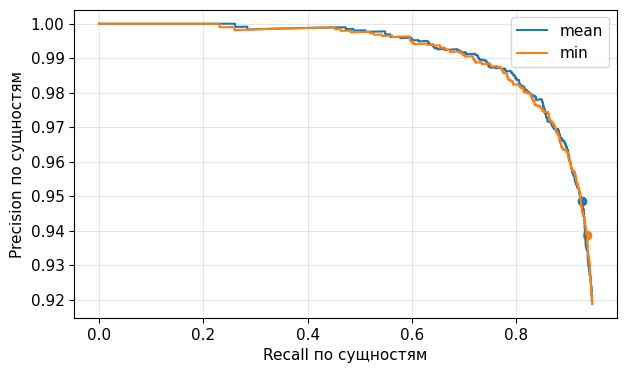

{
  "split": "validation",
  "confidence": {
    "mean": {
      "threshold_zero": {
        "threshold": 0.0,
        "n_pred": 4236,
        "n_match": 3892,
        "precision": 0.9187913125590179,
        "recall": 0.9453485547728929,
        "f1_micro": 0.9318807614030887
      },
      "best_validation": {
        "threshold": 0.843644917011261,
        "n_pred": 4022,
        "n_match": 3815,
        "precision": 0.9485330681253108,
        "recall": 0.9266456157396162,
        "f1_micro": 0.9374616046197322
      },
      "delta_f1_micro": 0.005580843216643427
    },
    "min": {
      "threshold_zero": {
        "threshold": 0.0,
        "n_pred": 4236,
        "n_match": 3892,
        "precision": 0.9187913125590179,
        "recall": 0.9453485547728929,
        "f1_micro": 0.9318807614030887
      },
      "best_validation": {
        "threshold": 0.6339232921600342,
        "n_pred": 4105,
        "n_match": 3853,
        "precision": 0.9386114494518879,
        "recall": 0

In [34]:
if '6.5' in BONUS_TASKS:
    def span_pr_curve(gold_tags, pred_tags, word_probs, confidence):
        # Ключ включает номер предложения, границы и тип сущности.
        gold_spans = {(i, *span) for i, tags in enumerate(gold_tags) for span in bio_to_spans(tags)}
        ranked = []
        for i, (tags, probs) in enumerate(zip(pred_tags, word_probs, strict=True)):
            for start, end, kind in bio_to_spans(tags):
                score = float(confidence(probs[start:end]))
                ranked.append((score, (i, start, end, kind) in gold_spans))
        ranked.sort(key=lambda item: item[0], reverse=True)

        def point(threshold, kept, matched):
            return {
                'threshold': threshold, 'n_pred': kept, 'n_match': matched,
                'precision': matched / kept if kept else 0.0,
                'recall': matched / len(gold_spans) if gold_spans else 0.0,
                'f1_micro': 2 * matched / (kept + len(gold_spans)) if kept + len(gold_spans) else 0.0,
            }

        curve = []
        kept = matched = 0
        # Спаны с равной уверенностью проходят порог одновременно.
        for threshold, group in groupby(ranked, key=lambda item: item[0]):
            for _, is_match in group:
                kept += 1
                matched += is_match
            curve.append(point(threshold, kept, matched))
        if not curve or curve[-1]['threshold'] > 0:
            curve.append(point(0.0, kept, matched))
        return curve

    tags_with_probs, word_probs = predict_word_tags(model, val_tokens, return_probs=True)
    threshold_results = {}
    plt.figure(figsize=(7, 4))
    for name, aggregate in [('mean', np.mean), ('min', min)]:
        curve = span_pr_curve(val_gold, tags_with_probs, word_probs, aggregate)
        baseline_point = curve[-1]
        assert math.isclose(baseline_point['f1_micro'], val_scores['f1_micro'], abs_tol=1e-9)
        best = max(curve, key=lambda p: (p['f1_micro'], p['recall'], -p['threshold']))
        threshold_results[name] = {
            'threshold_zero': baseline_point,
            'best_validation': best,
            'delta_f1_micro': best['f1_micro'] - baseline_point['f1_micro'],
        }
        plt.plot([0.0] + [p['recall'] for p in curve],
                 [1.0] + [p['precision'] for p in curve], label=name)
        plt.scatter(best['recall'], best['precision'])
    plt.xlabel('Recall по сущностям')
    plt.ylabel('Precision по сущностям')
    plt.grid(alpha=0.3)
    plt.legend()
    plt.show()

    bonus_65 = {'split': 'validation', 'confidence': threshold_results}
    print(json.dumps(bonus_65, indent=2, ensure_ascii=False))

    bonus_results = {task: globals()[name] for task in sorted(BONUS_TASKS)
                     if (name := 'bonus_' + task.replace('.', '')) in globals()}
    bonus_path = ARTIFACTS / 'bonus_metrics.json'
    bonus_path.write_text(json.dumps(json_ready(bonus_results), ensure_ascii=False, indent=2), encoding='utf-8')
    print(f'Метрики бонусов: {bonus_path}')

**Вопрос.** Какой порог дает лучший F1 и сколько он добавляет к порогу 0? Чем отличаются средняя и минимальная уверенность? Почему порог по уверенности не может поднять recall?

**Ответ:**

Лучший результат на validation дала средняя уверенность слов спана с порогом 0,8436: F1 вырос с 0,9319 до 0,9375 (+0,0056). Precision вырос с 0,9188 до 0,9485, а recall упал с 0,9453 до 0,9266. Среднее допускает одно неуверенное слово среди нескольких уверенных. Минимум определяется самым неуверенным словом. Для него лучший порог составил 0,6339, а F1 — 0,9372 (+0,0054). Фильтрация может только удалить уже предсказанные спаны, поэтому число найденных истинных сущностей и recall не могут вырасти. Порог выбран и оценён на validation, выигрыш на независимом test здесь не измерялся.